# Methods S1: Expression classification, GO enrichment and TSI visualization

#**Step 0**: Initial Setup

In [1]:
!mkdir ChickpeaOmicsExplorerInput

In [2]:
!ls

ChickpeaOmicsExplorerInput  sample_data


In [5]:
!pip install gdown
import gdown
file_id = '1tIMAvwJG2h3MLxCXwr73NQELlZg-e--G'
gdown.download(f'https://drive.google.com/uc?export=download&id={file_id}', '/content/ChickpeaOmicsExplorerInput.zip', quiet=False)
!unzip /content/ChickpeaOmicsExplorerInput.zip -d /content/

Downloading...
From (original): https://drive.google.com/uc?export=download&id=1tIMAvwJG2h3MLxCXwr73NQELlZg-e--G
From (redirected): https://drive.google.com/uc?export=download&id=1tIMAvwJG2h3MLxCXwr73NQELlZg-e--G&confirm=t&uuid=b98c164e-30e9-4a86-8dda-bcc9225bf100
To: /content/ChickpeaOmicsExplorerInput.zip
100%|██████████| 70.4M/70.4M [00:00<00:00, 133MB/s]


Archive:  /content/ChickpeaOmicsExplorerInput.zip
  inflating: /content/go-basic.obo   
  inflating: /content/__MACOSX/._go-basic.obo  
  inflating: /content/Supplementary File 1.7.xlsx  
  inflating: /content/__MACOSX/._Supplementary File 1.7.xlsx  
  inflating: /content/Supplementary File 1.xlsx  
  inflating: /content/__MACOSX/._Supplementary File 1.xlsx  
  inflating: /content/Supplementary File 7.xlsx  
  inflating: /content/__MACOSX/._Supplementary File 7.xlsx  


In [6]:
!pip install openpyxl deap openpyxl goatools xlsxwriter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.9/250.9 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.1/93.1 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 93.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 70.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 140.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.3/233.3 kB 24.8 MB/s eta 0:00:00


In [7]:
!cp "/content/Supplementary File 1.xlsx" ChickpeaOmicsExplorerInput/

# **STEP 1**: Import Dependencies

In [8]:
# ========================
# Core Libraries
# ========================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ========================
# Standard Utilities
# ========================
import os
import re
import time
import math
import random
import requests
import warnings
from IPython.display import HTML

warnings.filterwarnings('ignore')

# ========================
# Scikit-learn: Model Selection
# ========================
from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    GridSearchCV,
    RandomizedSearchCV,
    cross_val_score
)

# ========================
# Scikit-learn: Preprocessing
# ========================
from sklearn.preprocessing import (
    StandardScaler,
    MultiLabelBinarizer,
    label_binarize
)

# ========================
# Scikit-learn: Models
# ========================
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.multiclass import OneVsRestClassifier

# ========================
# Scikit-learn: Pipeline
# ========================
from sklearn.pipeline import Pipeline

# ========================
# Scikit-learn: Metrics
# ========================
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)

# ========================
# Functional Annotation
# ========================
from deap import base, creator, tools
from goatools import obo_parser
from goatools.go_enrichment import GOEnrichmentStudy

# ========================
# XGBoost (Auto-install if missing)
# ========================
try:
    from xgboost import XGBClassifier
except ImportError:
    import subprocess
    subprocess.check_call(['pip', 'install', 'xgboost'])
    from xgboost import XGBClassifier

print("All ML dependencies loaded successfully.")

All ML dependencies loaded successfully.


# **STEP 2**: Data Collection

In [9]:
data = pd.read_excel('ChickpeaOmicsExplorerInput/Supplementary File 1.xlsx')

data = data.drop_duplicates()

# Retain a transcript-to-chromosome mapping for leakage-resistant validation.
# The coordinate itself is not used as a model feature. Unplaced scaffolds are
# kept together as one conservative validation group.
chromosome_by_transcript = (
    data[['Transcript id', 'Genomic Coordinates']]
    .drop_duplicates(subset=['Transcript id'])
    .set_index('Transcript id')['Genomic Coordinates']
    .astype('string')
    .str.split(':', n=1).str[0]
)
major_chromosomes = {f'Ca_{i}' for i in range(1, 9)}
chromosome_by_transcript = chromosome_by_transcript.where(
    chromosome_by_transcript.isin(major_chromosomes),
    'Unplaced'
)

conflicting_duplicates = data[data.duplicated(subset=['Transcript id'], keep=False)]

if not conflicting_duplicates.empty:
    print(f"Found {len(conflicting_duplicates)} rows with the same 'Transcript id' but differing values in other columns.")
    print("Here are the differing duplicates:")
    print(conflicting_duplicates)
else:
    print("All duplicated removed.")
    print(f"Data shape after removing duplicates: {data.shape}")
    print("Proceeding with data slicing...\n")

    data = data.iloc[:, [0] + list(range(5, data.shape[1]))]

    print(data.head())


All duplicated removed.
Data shape after removing duplicates: (38818, 42)
Proceeding with data slicing...

  Transcript id      GS      S     R    Rtip      RH      YL      ML    Brac  \
0      Ca_00001   8.420  2.387  0.82   0.897   4.407   1.973   2.593   0.883   
1      Ca_00002  10.027  4.237  2.85   2.043   3.767   3.873   3.250   1.430   
2      Ca_00003   8.710  8.277  4.88   9.567  11.913   7.833  10.280   8.477   
3      Ca_00004   9.190  7.723  9.97  10.910   7.267  10.287   9.983  10.923   
4      Ca_00005   0.490  1.543  0.12   0.553   0.350   1.663   1.197   0.600   

      SAM  ...    5DAP   10DAP    20DAP  30DAP    Nod  \
0   4.027  ...   1.767   2.937   18.740  0.690  0.163   
1   4.117  ...   5.760   5.103   13.215  1.490  0.423   
2  21.220  ...  11.680  13.030   69.265  6.505  2.287   
3  11.047  ...  18.830  15.467  203.315  5.455  2.187   
4   1.053  ...   0.437   2.123   51.260  1.800  1.000   

                                        Cds Sequence  \
0  ATGGCACGTG

In [10]:
data.tail()

,Transcript id,GS,S,R,Rtip,RH,YL,ML,Brac,SAM,...,5DAP,10DAP,20DAP,30DAP,Nod,Cds Sequence,Peptide Sequence,Transcript Sequence,Genomic Sequence,Promoter Sequence
38865,Ca_38814,0.827,0.180,1.41,0.563,0.000,1.857,0.907,2.570,2.753,...,0.447,0.070,0.000,0.20,0.270,NaN,NaN,NaN,NaN,NaN
38866,Ca_38815,0.120,0.000,0.00,0.467,0.000,0.013,0.000,0.023,0.000,...,1.987,3.093,0.000,0.00,0.040,NaN,NaN,NaN,NaN,NaN
38867,Ca_38816,1.090,0.053,0.00,0.353,0.110,0.937,1.197,0.253,0.187,...,0.143,0.197,0.000,0.19,0.550,NaN,NaN,NaN,NaN,NaN
38868,Ca_38817,0.000,0.000,0.00,0.000,0.000,0.000,0.037,0.070,0.000,...,0.000,0.000,0.000,0.00,0.117,NaN,NaN,NaN,NaN,NaN
38869,Ca_38818,6.237,0.000,60.06,22.730,0.177,5.103,2.003,11.520,3.317,...,9.710,15.940,1322.815,1.79,7.260,NaN,NaN,NaN,NaN,NaN


# **STEP 3**: PreProcessing

In [11]:
missing_values = data.isnull().sum()
print(missing_values[missing_values > 0])
data = data.iloc[:, :-5]
data = data.dropna() #drop or fill mean

print(f'Dataset shape after handling missing values: {data.shape}')

Cds Sequence           10549
Peptide Sequence       10549
Transcript Sequence    10549
Genomic Sequence       10549
Promoter Sequence      10549
dtype: int64
Dataset shape after handling missing values: (38818, 33)


In [12]:
# Retain all genes after missing-value handling; no minimum FPKM filter is applied.
# 20DAP is excluded from consideration because its expression values are inflated.
tissue_cols = ['GS','S','R','Rtip','RH','YL','ML','Brac','SAM',
               'FB1','FB2','FB3','FB4','FL1','FL2','FL3','FL4','FL5',
               'Cal','Cor','And','Gyn','Pedi','PodSh','SdCt','Emb',
               'Endo','5DAP','10DAP','30DAP','Nod']

data_expressed = data[['Transcript id'] + tissue_cols].copy()
print(f"Genes retained without FPKM thresholding: {len(data_expressed)} / {len(data)}")


Genes retained without FPKM thresholding: 38818 / 38818


In [13]:
data_expressed

,Transcript id,GS,S,R,Rtip,RH,YL,ML,Brac,SAM,...,Gyn,Pedi,PodSh,SdCt,Emb,Endo,5DAP,10DAP,30DAP,Nod
0,Ca_00001,8.420,2.387,0.82,0.897,4.407,1.973,2.593,0.883,4.027,...,4.060,2.750,2.600,3.510,1.687,2.660,1.767,2.937,0.690,0.163
1,Ca_00002,10.027,4.237,2.85,2.043,3.767,3.873,3.250,1.430,4.117,...,7.290,3.333,5.180,4.987,2.417,3.807,5.760,5.103,1.490,0.423
2,Ca_00003,8.710,8.277,4.88,9.567,11.913,7.833,10.280,8.477,21.220,...,8.343,8.360,17.483,7.970,5.280,9.057,11.680,13.030,6.505,2.287
3,Ca_00004,9.190,7.723,9.97,10.910,7.267,10.287,9.983,10.923,11.047,...,14.190,17.300,17.227,11.223,6.767,13.673,18.830,15.467,5.455,2.187
4,Ca_00005,0.490,1.543,0.12,0.553,0.350,1.663,1.197,0.600,1.053,...,0.867,0.690,1.533,0.720,0.310,0.107,0.437,2.123,1.800,1.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38865,Ca_38814,0.827,0.180,1.41,0.563,0.000,1.857,0.907,2.570,2.753,...,0.177,1.290,0.000,1.240,3.163,7.740,0.447,0.070,0.200,0.270
38866,Ca_38815,0.120,0.000,0.00,0.467,0.000,0.013,0.000,0.023,0.000,...,2.580,0.010,4.737,0.067,0.000,0.000,1.987,3.093,0.000,0.040
38867,Ca_38816,1.090,0.053,0.00,0.353,0.110,0.937,1.197,0.253,0.187,...,0.000,0.573,2.540,0.000,0.323,0.220,0.143,0.197,0.190,0.550
38868,Ca_38817,0.000,0.000,0.00,0.000,0.000,0.000,0.037,0.070,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.117


In [14]:
# Log2(FPKM + 1) transform the retained tissue-expression columns.
data_expressed[tissue_cols] = np.log2(data_expressed[tissue_cols] + 1)


In [15]:
data_expressed

,Transcript id,GS,S,R,Rtip,RH,YL,ML,Brac,SAM,...,Gyn,Pedi,PodSh,SdCt,Emb,Endo,5DAP,10DAP,30DAP,Nod
0,Ca_00001,3.235727,1.760008,0.863938,0.923720,2.434828,1.571919,1.845189,0.913033,2.329698,...,2.339137,1.906891,1.847997,2.173127,1.425996,1.871844,1.468323,1.977097,0.757023,0.217851
1,Ca_00002,3.462968,2.388741,1.944858,1.605494,2.253082,2.284810,2.087463,1.280956,2.355298,...,3.051372,2.115366,2.627607,2.581833,1.772730,2.265137,2.757023,2.609519,1.316146,0.508936
2,Ca_00003,3.279471,3.213658,2.555816,3.401494,3.690752,3.142904,3.495695,3.244430,4.473787,...,3.223886,3.226509,4.208127,3.165108,2.650765,3.330128,3.664483,3.810443,2.907852,1.716771
3,Ca_00004,3.349082,3.124824,3.455492,3.574102,3.047364,3.496590,3.457200,3.575675,3.590602,...,3.925050,4.193772,4.188005,3.611527,2.957357,3.875092,4.309613,4.041506,2.690417,1.672199
4,Ca_00005,0.575312,1.346531,0.163499,0.635058,0.432959,1.413052,1.135535,0.678072,1.037734,...,0.900722,0.757023,1.340847,0.782409,0.389567,0.146655,0.523060,1.642933,1.485427,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38865,Ca_38814,0.869477,0.238787,1.269033,0.644318,0.000000,1.514501,0.931305,1.835924,1.908044,...,0.235114,1.195348,0.000000,1.163499,2.057624,3.127633,0.533065,0.097611,0.263034,0.344828
38866,Ca_38815,0.163499,0.000000,0.000000,0.552869,0.000000,0.018634,0.000000,0.032806,0.000000,...,1.839960,0.014355,2.520297,0.093560,0.000000,0.000000,1.578697,2.033159,0.000000,0.056584
38867,Ca_38816,1.063503,0.074505,0.000000,0.436162,0.150560,0.953824,1.135535,0.325386,0.247320,...,0.000000,0.653519,1.823749,0.000000,0.403813,0.286881,0.192825,0.259423,0.250962,0.632268
38868,Ca_38817,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.052416,0.097611,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.159629


In [16]:
def multiColumn(data):
  cols_RT = ['Nod', 'RH', 'R', 'Rtip']
  data['RT'] = data[cols_RT].mean(axis=1) #/4

  cols_FP = ['And', 'Gyn', 'Cor']
  data['FP'] = data[cols_FP].mean(axis=1) #/3

  cols_GT = ['GS', 'Pedi', 'S', 'ML', 'Brac', 'Cal', 'YL', 'PodSh']
  data['GT'] = data[cols_GT].mean(axis=1) #/8

  cols_FDS = ['SAM', 'FL1', 'FL2', 'FL3', 'FL4', 'FL5', 'FB1', 'FB2', 'FB3', 'FB4']
  data['FDS'] = data[cols_FDS].mean(axis=1) #/10

  # 20DAP is omitted because its inflated values would bias the seed-tissue mean.
  cols_ST = ['Endo', 'Emb', '10DAP', '5DAP', 'SdCt', '30DAP']
  data['ST'] = data[cols_ST].mean(axis=1) #/6

  return data[['RT', 'FP', 'GT', 'FDS', 'ST']]


In [17]:
multiColumn(data_expressed)

,RT,FP,GT,FDS,ST
0,1.110084,1.364994,1.750560,1.710916,1.612235
1,1.578093,2.183998,2.220932,2.106893,2.217065
2,2.841208,3.249552,3.368885,3.853562,3.254796
3,2.937289,4.355468,3.708105,4.106321,3.580919
4,0.557879,1.350099,1.031427,0.872710,0.828342
...,...,...,...,...,...
38865,0.564545,0.121136,0.961796,0.763008,1.207078
38866,0.152363,1.841436,0.780821,0.010595,0.617569
38867,0.304747,0.146807,0.793560,1.579022,0.232317
38868,0.039907,0.000000,0.018753,0.000000,0.000000


In [18]:
data=data_expressed.copy()

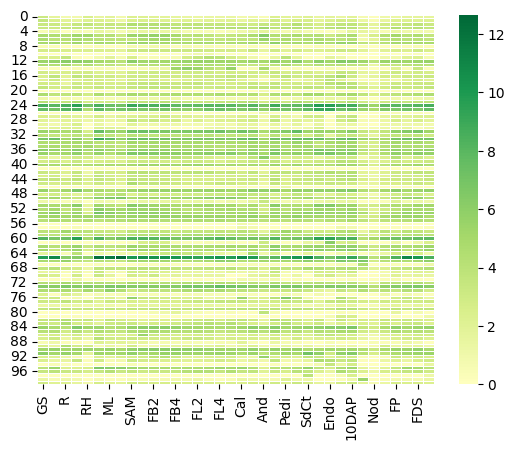

In [19]:
# The Heatmap
sns.heatmap(data.iloc[:100, 1:], cmap='RdYlGn', center=0, annot=False, linewidths=0.5)

plt.show()

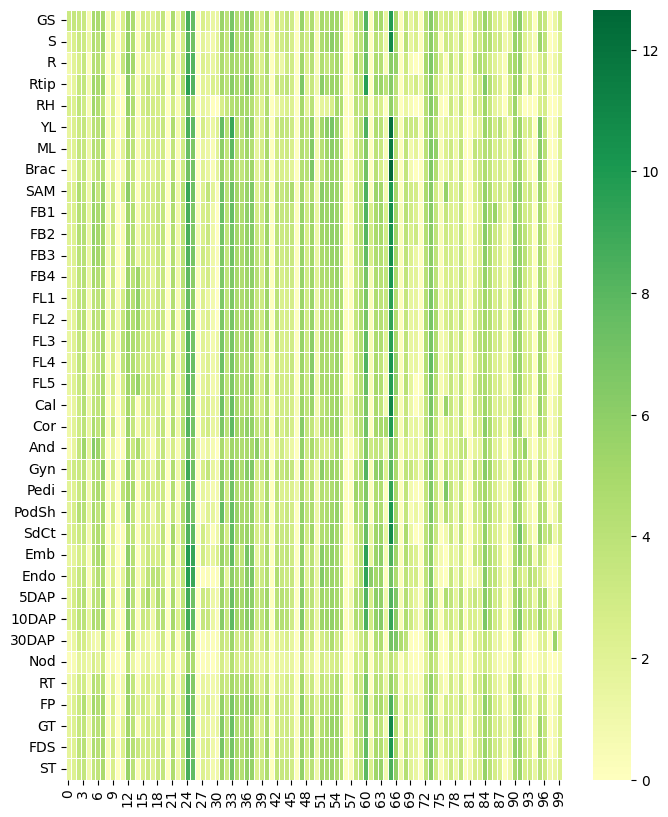

In [20]:
# The Heatmap
plt.figure(figsize=(8, 10))
sns.heatmap(data.iloc[:100, 1:].T, cmap='RdYlGn', center=0, annot=False, linewidths=0.5)

plt.show()

In [21]:
data

,Transcript id,GS,S,R,Rtip,RH,YL,ML,Brac,SAM,...,Endo,5DAP,10DAP,30DAP,Nod,RT,FP,GT,FDS,ST
0,Ca_00001,3.235727,1.760008,0.863938,0.923720,2.434828,1.571919,1.845189,0.913033,2.329698,...,1.871844,1.468323,1.977097,0.757023,0.217851,1.110084,1.364994,1.750560,1.710916,1.612235
1,Ca_00002,3.462968,2.388741,1.944858,1.605494,2.253082,2.284810,2.087463,1.280956,2.355298,...,2.265137,2.757023,2.609519,1.316146,0.508936,1.578093,2.183998,2.220932,2.106893,2.217065
2,Ca_00003,3.279471,3.213658,2.555816,3.401494,3.690752,3.142904,3.495695,3.244430,4.473787,...,3.330128,3.664483,3.810443,2.907852,1.716771,2.841208,3.249552,3.368885,3.853562,3.254796
3,Ca_00004,3.349082,3.124824,3.455492,3.574102,3.047364,3.496590,3.457200,3.575675,3.590602,...,3.875092,4.309613,4.041506,2.690417,1.672199,2.937289,4.355468,3.708105,4.106321,3.580919
4,Ca_00005,0.575312,1.346531,0.163499,0.635058,0.432959,1.413052,1.135535,0.678072,1.037734,...,0.146655,0.523060,1.642933,1.485427,1.000000,0.557879,1.350099,1.031427,0.872710,0.828342
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38865,Ca_38814,0.869477,0.238787,1.269033,0.644318,0.000000,1.514501,0.931305,1.835924,1.908044,...,3.127633,0.533065,0.097611,0.263034,0.344828,0.564545,0.121136,0.961796,0.763008,1.207078
38866,Ca_38815,0.163499,0.000000,0.000000,0.552869,0.000000,0.018634,0.000000,0.032806,0.000000,...,0.000000,1.578697,2.033159,0.000000,0.056584,0.152363,1.841436,0.780821,0.010595,0.617569
38867,Ca_38816,1.063503,0.074505,0.000000,0.436162,0.150560,0.953824,1.135535,0.325386,0.247320,...,0.286881,0.192825,0.259423,0.250962,0.632268,0.304747,0.146807,0.793560,1.579022,0.232317
38868,Ca_38817,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.052416,0.097611,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.159629,0.039907,0.000000,0.018753,0.000000,0.000000


In [22]:
X = data.iloc[:, :]

print(f'Features shape: {X.shape} ')
"""Target shape {y.shape}"""


Features shape: (38818, 37) 


'Target shape {y.shape}'

In [23]:
data

,Transcript id,GS,S,R,Rtip,RH,YL,ML,Brac,SAM,...,Endo,5DAP,10DAP,30DAP,Nod,RT,FP,GT,FDS,ST
0,Ca_00001,3.235727,1.760008,0.863938,0.923720,2.434828,1.571919,1.845189,0.913033,2.329698,...,1.871844,1.468323,1.977097,0.757023,0.217851,1.110084,1.364994,1.750560,1.710916,1.612235
1,Ca_00002,3.462968,2.388741,1.944858,1.605494,2.253082,2.284810,2.087463,1.280956,2.355298,...,2.265137,2.757023,2.609519,1.316146,0.508936,1.578093,2.183998,2.220932,2.106893,2.217065
2,Ca_00003,3.279471,3.213658,2.555816,3.401494,3.690752,3.142904,3.495695,3.244430,4.473787,...,3.330128,3.664483,3.810443,2.907852,1.716771,2.841208,3.249552,3.368885,3.853562,3.254796
3,Ca_00004,3.349082,3.124824,3.455492,3.574102,3.047364,3.496590,3.457200,3.575675,3.590602,...,3.875092,4.309613,4.041506,2.690417,1.672199,2.937289,4.355468,3.708105,4.106321,3.580919
4,Ca_00005,0.575312,1.346531,0.163499,0.635058,0.432959,1.413052,1.135535,0.678072,1.037734,...,0.146655,0.523060,1.642933,1.485427,1.000000,0.557879,1.350099,1.031427,0.872710,0.828342
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38865,Ca_38814,0.869477,0.238787,1.269033,0.644318,0.000000,1.514501,0.931305,1.835924,1.908044,...,3.127633,0.533065,0.097611,0.263034,0.344828,0.564545,0.121136,0.961796,0.763008,1.207078
38866,Ca_38815,0.163499,0.000000,0.000000,0.552869,0.000000,0.018634,0.000000,0.032806,0.000000,...,0.000000,1.578697,2.033159,0.000000,0.056584,0.152363,1.841436,0.780821,0.010595,0.617569
38867,Ca_38816,1.063503,0.074505,0.000000,0.436162,0.150560,0.953824,1.135535,0.325386,0.247320,...,0.286881,0.192825,0.259423,0.250962,0.632268,0.304747,0.146807,0.793560,1.579022,0.232317
38868,Ca_38817,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.052416,0.097611,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.159629,0.039907,0.000000,0.018753,0.000000,0.000000


# **STEP 4**: Copying Processed data to new excel files

In [24]:
rearrange_order = ['Transcript id', 'R', 'RH', 'Rtip', 'Nod', 'RT', 'GS', 'Pedi', 'S', 'ML', 'Brac', 'Cal', 'YL', 'PodSh', 'GT', 'And', 'Gyn', 'Cor', 'FP', 'SAM', 'FL1', 'FL2', 'FL3', 'FL4', 'FL5', 'FB1', 'FB2', 'FB3', 'FB4', 'FDS', 'Endo', 'Emb', '10DAP', '5DAP', 'SdCt', '30DAP', 'ST']
data = data[rearrange_order]

data.to_excel('Supplementary File 1.1.xlsx', index=False)


# **STEP 5**: Applying Pairwise Difference

In [25]:
# Specify only the columns you want to compare (this naturally skips 'Transcript id')
target_columns = ['RT', 'GT', 'FP', 'FDS', 'ST']

for dv in [1, 1.5, 2, 2.5, 3]:

    # Define a temporary function that uses the current 'dv' safely
    def check_threshold(row, threshold=dv):
        diffs = [
            abs(row['RT'] - row['GT']), abs(row['RT'] - row['FP']),
            abs(row['RT'] - row['FDS']), abs(row['RT'] - row['ST']),
            abs(row['GT'] - row['FP']), abs(row['GT'] - row['FDS']),
            abs(row['GT'] - row['ST']), abs(row['FP'] - row['FDS']),
            abs(row['FP'] - row['ST']), abs(row['FDS'] - row['ST'])
        ]
        return 1 if any(d > threshold for d in diffs) else 0

    # Apply the calculation ONLY to the 5 target columns
    count = data_expressed[target_columns].apply(check_threshold, axis=1).sum()

    # Calculate percentages
    total_genes = len(data_expressed)
    nhk = count
    hk = total_genes - count

    print(f"diff={dv} ({2**dv:.1f}-fold) | HK={hk} ({(hk/total_genes)*100:.1f}%) | NHK={nhk} ({(nhk/total_genes)*100:.1f}%)")

diff=1 (2.0-fold) | HK=19372 (49.9%) | NHK=19446 (50.1%)
diff=1.5 (2.8-fold) | HK=26604 (68.5%) | NHK=12214 (31.5%)
diff=2 (4.0-fold) | HK=31048 (80.0%) | NHK=7770 (20.0%)
diff=2.5 (5.7-fold) | HK=33758 (87.0%) | NHK=5060 (13.0%)
diff=3 (8.0-fold) | HK=35505 (91.5%) | NHK=3313 (8.5%)


In [26]:
data_expressed

,Transcript id,GS,S,R,Rtip,RH,YL,ML,Brac,SAM,...,Endo,5DAP,10DAP,30DAP,Nod,RT,FP,GT,FDS,ST
0,Ca_00001,3.235727,1.760008,0.863938,0.923720,2.434828,1.571919,1.845189,0.913033,2.329698,...,1.871844,1.468323,1.977097,0.757023,0.217851,1.110084,1.364994,1.750560,1.710916,1.612235
1,Ca_00002,3.462968,2.388741,1.944858,1.605494,2.253082,2.284810,2.087463,1.280956,2.355298,...,2.265137,2.757023,2.609519,1.316146,0.508936,1.578093,2.183998,2.220932,2.106893,2.217065
2,Ca_00003,3.279471,3.213658,2.555816,3.401494,3.690752,3.142904,3.495695,3.244430,4.473787,...,3.330128,3.664483,3.810443,2.907852,1.716771,2.841208,3.249552,3.368885,3.853562,3.254796
3,Ca_00004,3.349082,3.124824,3.455492,3.574102,3.047364,3.496590,3.457200,3.575675,3.590602,...,3.875092,4.309613,4.041506,2.690417,1.672199,2.937289,4.355468,3.708105,4.106321,3.580919
4,Ca_00005,0.575312,1.346531,0.163499,0.635058,0.432959,1.413052,1.135535,0.678072,1.037734,...,0.146655,0.523060,1.642933,1.485427,1.000000,0.557879,1.350099,1.031427,0.872710,0.828342
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38865,Ca_38814,0.869477,0.238787,1.269033,0.644318,0.000000,1.514501,0.931305,1.835924,1.908044,...,3.127633,0.533065,0.097611,0.263034,0.344828,0.564545,0.121136,0.961796,0.763008,1.207078
38866,Ca_38815,0.163499,0.000000,0.000000,0.552869,0.000000,0.018634,0.000000,0.032806,0.000000,...,0.000000,1.578697,2.033159,0.000000,0.056584,0.152363,1.841436,0.780821,0.010595,0.617569
38867,Ca_38816,1.063503,0.074505,0.000000,0.436162,0.150560,0.953824,1.135535,0.325386,0.247320,...,0.286881,0.192825,0.259423,0.250962,0.632268,0.304747,0.146807,0.793560,1.579022,0.232317
38868,Ca_38817,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.052416,0.097611,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.159629,0.039907,0.000000,0.018753,0.000000,0.000000


In [27]:
data

,Transcript id,R,RH,Rtip,Nod,RT,GS,Pedi,S,ML,...,FB3,FB4,FDS,Endo,Emb,10DAP,5DAP,SdCt,30DAP,ST
0,Ca_00001,0.863938,2.434828,0.923720,0.217851,1.110084,3.235727,1.906891,1.760008,1.845189,...,1.807355,1.597889,1.710916,1.871844,1.425996,1.977097,1.468323,2.173127,0.757023,1.612235
1,Ca_00002,1.944858,2.253082,1.605494,0.508936,1.578093,3.462968,2.115366,2.388741,2.087463,...,2.250052,1.859970,2.106893,2.265137,1.772730,2.609519,2.757023,2.581833,1.316146,2.217065
2,Ca_00003,2.555816,3.690752,3.401494,1.716771,2.841208,3.279471,3.226509,3.213658,3.495695,...,3.972049,3.757343,3.853562,3.330128,2.650765,3.810443,3.664483,3.165108,2.907852,3.254796
3,Ca_00004,3.455492,3.047364,3.574102,1.672199,2.937289,3.349082,4.193772,3.124824,3.457200,...,4.145107,4.162935,4.106321,3.875092,2.957357,4.041506,4.309613,3.611527,2.690417,3.580919
4,Ca_00005,0.163499,0.432959,0.635058,1.000000,0.557879,0.575312,0.757023,1.346531,1.135535,...,1.323658,1.220330,0.872710,0.146655,0.389567,1.642933,0.523060,0.782409,1.485427,0.828342
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38865,Ca_38814,1.269033,0.000000,0.644318,0.344828,0.564545,0.869477,1.195348,0.238787,0.931305,...,0.000000,0.176323,0.763008,3.127633,2.057624,0.097611,0.533065,1.163499,0.263034,1.207078
38866,Ca_38815,0.000000,0.000000,0.552869,0.056584,0.152363,0.163499,0.014355,0.000000,0.000000,...,0.014355,0.024320,0.010595,0.000000,0.000000,2.033159,1.578697,0.093560,0.000000,0.617569
38867,Ca_38816,0.000000,0.150560,0.436162,0.632268,0.304747,1.063503,0.653519,0.074505,1.135535,...,0.809826,1.030689,1.579022,0.286881,0.403813,0.259423,0.192825,0.000000,0.250962,0.232317
38868,Ca_38817,0.000000,0.000000,0.000000,0.159629,0.039907,0.000000,0.000000,0.000000,0.052416,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [28]:
difference_value=1

In [29]:
def calculate_difference(row):
    differences = []

    differences.append(abs(row['RT'] - row['GT']))
    differences.append(abs(row['RT'] - row['FP']))
    differences.append(abs(row['RT'] - row['FDS']))
    differences.append(abs(row['RT'] - row['ST']))

    differences.append(abs(row['GT'] - row['FP']))
    differences.append(abs(row['GT'] - row['FDS']))
    differences.append(abs(row['GT'] - row['ST']))

    differences.append(abs(row['FP'] - row['FDS']))
    differences.append(abs(row['FP'] - row['ST']))

    differences.append(abs(row['FDS'] - row['ST']))

    return 1 if any(diff > difference_value for diff in differences) else 0

data['Difference'] = data.apply(calculate_difference, axis=1)

print(data)

      Transcript id         R        RH      Rtip       Nod        RT  \
0          Ca_00001  0.863938  2.434828  0.923720  0.217851  1.110084   
1          Ca_00002  1.944858  2.253082  1.605494  0.508936  1.578093   
2          Ca_00003  2.555816  3.690752  3.401494  1.716771  2.841208   
3          Ca_00004  3.455492  3.047364  3.574102  1.672199  2.937289   
4          Ca_00005  0.163499  0.432959  0.635058  1.000000  0.557879   
...             ...       ...       ...       ...       ...       ...   
38865      Ca_38814  1.269033  0.000000  0.644318  0.344828  0.564545   
38866      Ca_38815  0.000000  0.000000  0.552869  0.056584  0.152363   
38867      Ca_38816  0.000000  0.150560  0.436162  0.632268  0.304747   
38868      Ca_38817  0.000000  0.000000  0.000000  0.159629  0.039907   
38869      Ca_38818  5.932156  0.235114  4.568640  3.046142  3.445513   

             GS      Pedi         S        ML  ...       FB4       FDS  \
0      3.235727  1.906891  1.760008  1.845189  ..

In [30]:
difference_counts = data['Difference'].value_counts()

print(difference_counts)
#1 = Non House keeping, 0 = Housekeeping

Difference
1    19446
0    19372
Name: count, dtype: int64


In [31]:
thresholds = {}

for column in data.columns[1:]:
    min_val = data[column].min()
    max_val = data[column].max()
    mean_val = data[column].mean()
    thresholds[column] = {'min': min_val, 'max': max_val, 'mean': mean_val}

print(thresholds)

data.to_excel('Supplementary File 1.2.xlsx', index=False)

{'R': {'min': np.float64(0.0), 'max': np.float64(15.037389515222127), 'mean': np.float64(1.9487632588802377)}, 'RH': {'min': np.float64(0.0), 'max': np.float64(13.58129557348577), 'mean': np.float64(1.6803383061392492)}, 'Rtip': {'min': np.float64(0.0), 'max': np.float64(13.172470795098167), 'mean': np.float64(1.984950328492897)}, 'Nod': {'min': np.float64(0.0), 'max': np.float64(16.262750088204854), 'mean': np.float64(1.2064122697589392)}, 'RT': {'min': np.float64(0.0), 'max': np.float64(11.240058245719297), 'mean': np.float64(1.705116040817831)}, 'GS': {'min': np.float64(0.0), 'max': np.float64(14.228346957298642), 'mean': np.float64(2.1424456316701375)}, 'Pedi': {'min': np.float64(0.0), 'max': np.float64(14.651632902582142), 'mean': np.float64(2.0541993570253014)}, 'S': {'min': np.float64(0.0), 'max': np.float64(14.739605007914006), 'mean': np.float64(2.030175893578362)}, 'ML': {'min': np.float64(0.0), 'max': np.float64(15.649790576381251), 'mean': np.float64(2.00137166323252)}, 'Br

In [32]:
thresholds

{'R': {'min': np.float64(0.0),
  'max': np.float64(15.037389515222127),
  'mean': np.float64(1.9487632588802377)},
 'RH': {'min': np.float64(0.0),
  'max': np.float64(13.58129557348577),
  'mean': np.float64(1.6803383061392492)},
 'Rtip': {'min': np.float64(0.0),
  'max': np.float64(13.172470795098167),
  'mean': np.float64(1.984950328492897)},
 'Nod': {'min': np.float64(0.0),
  'max': np.float64(16.262750088204854),
  'mean': np.float64(1.2064122697589392)},
 'RT': {'min': np.float64(0.0),
  'max': np.float64(11.240058245719297),
  'mean': np.float64(1.705116040817831)},
 'GS': {'min': np.float64(0.0),
  'max': np.float64(14.228346957298642),
  'mean': np.float64(2.1424456316701375)},
 'Pedi': {'min': np.float64(0.0),
  'max': np.float64(14.651632902582142),
  'mean': np.float64(2.0541993570253014)},
 'S': {'min': np.float64(0.0),
  'max': np.float64(14.739605007914006),
  'mean': np.float64(2.030175893578362)},
 'ML': {'min': np.float64(0.0),
  'max': np.float64(15.649790576381251),


In [33]:
data['Difference'].unique()

array([0, 1])

# **STEP 6**: Multi Class Classification

In [34]:
data

,Transcript id,R,RH,Rtip,Nod,RT,GS,Pedi,S,ML,...,FB4,FDS,Endo,Emb,10DAP,5DAP,SdCt,30DAP,ST,Difference
0,Ca_00001,0.863938,2.434828,0.923720,0.217851,1.110084,3.235727,1.906891,1.760008,1.845189,...,1.597889,1.710916,1.871844,1.425996,1.977097,1.468323,2.173127,0.757023,1.612235,0
1,Ca_00002,1.944858,2.253082,1.605494,0.508936,1.578093,3.462968,2.115366,2.388741,2.087463,...,1.859970,2.106893,2.265137,1.772730,2.609519,2.757023,2.581833,1.316146,2.217065,0
2,Ca_00003,2.555816,3.690752,3.401494,1.716771,2.841208,3.279471,3.226509,3.213658,3.495695,...,3.757343,3.853562,3.330128,2.650765,3.810443,3.664483,3.165108,2.907852,3.254796,1
3,Ca_00004,3.455492,3.047364,3.574102,1.672199,2.937289,3.349082,4.193772,3.124824,3.457200,...,4.162935,4.106321,3.875092,2.957357,4.041506,4.309613,3.611527,2.690417,3.580919,1
4,Ca_00005,0.163499,0.432959,0.635058,1.000000,0.557879,0.575312,0.757023,1.346531,1.135535,...,1.220330,0.872710,0.146655,0.389567,1.642933,0.523060,0.782409,1.485427,0.828342,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38865,Ca_38814,1.269033,0.000000,0.644318,0.344828,0.564545,0.869477,1.195348,0.238787,0.931305,...,0.176323,0.763008,3.127633,2.057624,0.097611,0.533065,1.163499,0.263034,1.207078,1
38866,Ca_38815,0.000000,0.000000,0.552869,0.056584,0.152363,0.163499,0.014355,0.000000,0.000000,...,0.024320,0.010595,0.000000,0.000000,2.033159,1.578697,0.093560,0.000000,0.617569,1
38867,Ca_38816,0.000000,0.150560,0.436162,0.632268,0.304747,1.063503,0.653519,0.074505,1.135535,...,1.030689,1.579022,0.286881,0.403813,0.259423,0.192825,0.000000,0.250962,0.232317,1
38868,Ca_38817,0.000000,0.000000,0.000000,0.159629,0.039907,0.000000,0.000000,0.000000,0.052416,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0


In [35]:
# Filter for Difference == 1
data.loc[data['Difference'] == 1, ['Transcript id', 'RT', 'GT', 'FP', 'FDS', 'ST', 'Difference']].to_excel('Supplementary File 1.3.xlsx', index=False)

PairWise - Absolute Difference

In [36]:
data

,Transcript id,R,RH,Rtip,Nod,RT,GS,Pedi,S,ML,...,FB4,FDS,Endo,Emb,10DAP,5DAP,SdCt,30DAP,ST,Difference
0,Ca_00001,0.863938,2.434828,0.923720,0.217851,1.110084,3.235727,1.906891,1.760008,1.845189,...,1.597889,1.710916,1.871844,1.425996,1.977097,1.468323,2.173127,0.757023,1.612235,0
1,Ca_00002,1.944858,2.253082,1.605494,0.508936,1.578093,3.462968,2.115366,2.388741,2.087463,...,1.859970,2.106893,2.265137,1.772730,2.609519,2.757023,2.581833,1.316146,2.217065,0
2,Ca_00003,2.555816,3.690752,3.401494,1.716771,2.841208,3.279471,3.226509,3.213658,3.495695,...,3.757343,3.853562,3.330128,2.650765,3.810443,3.664483,3.165108,2.907852,3.254796,1
3,Ca_00004,3.455492,3.047364,3.574102,1.672199,2.937289,3.349082,4.193772,3.124824,3.457200,...,4.162935,4.106321,3.875092,2.957357,4.041506,4.309613,3.611527,2.690417,3.580919,1
4,Ca_00005,0.163499,0.432959,0.635058,1.000000,0.557879,0.575312,0.757023,1.346531,1.135535,...,1.220330,0.872710,0.146655,0.389567,1.642933,0.523060,0.782409,1.485427,0.828342,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38865,Ca_38814,1.269033,0.000000,0.644318,0.344828,0.564545,0.869477,1.195348,0.238787,0.931305,...,0.176323,0.763008,3.127633,2.057624,0.097611,0.533065,1.163499,0.263034,1.207078,1
38866,Ca_38815,0.000000,0.000000,0.552869,0.056584,0.152363,0.163499,0.014355,0.000000,0.000000,...,0.024320,0.010595,0.000000,0.000000,2.033159,1.578697,0.093560,0.000000,0.617569,1
38867,Ca_38816,0.000000,0.150560,0.436162,0.632268,0.304747,1.063503,0.653519,0.074505,1.135535,...,1.030689,1.579022,0.286881,0.403813,0.259423,0.192825,0.000000,0.250962,0.232317,1
38868,Ca_38817,0.000000,0.000000,0.000000,0.159629,0.039907,0.000000,0.000000,0.000000,0.052416,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0


In [37]:
datasp = pd.read_excel('Supplementary File 1.3.xlsx')

tissue_cols = ['RT', 'GT', 'FP', 'FDS', 'ST']

# 3. Calculate core statistics
# .05 = 5th percentile, .50 = Median
stats = datasp[tissue_cols].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95])

# 4. Add advanced statistical metrics that are useful for expression analysis
stats.loc['var'] = datasp[tissue_cols].var()        # Variance (Spread of the data)
stats.loc['skew'] = datasp[tissue_cols].skew()      # Skewness (Asymmetry of the distribution)
stats.loc['kurtosis'] = datasp[tissue_cols].kurt()  # Kurtosis (Heaviness of the tails/outliers)

# 5. Display statistics
print("--- Comprehensive Statistical Summary ---")
# Rounding to 4 decimal places for cleaner output
print(stats.round(4))

--- Comprehensive Statistical Summary ---
                  RT          GT          FP         FDS          ST
count     19446.0000  19446.0000  19446.0000  19446.0000  19446.0000
mean          2.2791      2.9267      2.8543      3.1726      2.5672
std           1.7667      1.9952      1.9467      2.0097      1.8943
min           0.0000      0.0000      0.0000      0.0000      0.0000
5%            0.0166      0.0459      0.0248      0.0510      0.0372
25%           0.8987      1.3270      1.3195      1.6325      0.9969
50%           1.9956      2.8150      2.7574      3.1625      2.4081
75%           3.3307      4.2243      4.1258      4.4725      3.7817
95%           5.5759      6.4545      6.2890      6.6578      5.9610
max          11.2401     14.1823     12.2591     13.0058     11.7821
var           3.1212      3.9810      3.7897      4.0389      3.5882
skew          0.8957      0.5609      0.4954      0.4044      0.6781
kurtosis      0.7468      0.1490     -0.0725     -0.0451     

### Median Based Seggregation

In [38]:
# =================================================================
# CELL 1: Diagnostic Statistics + Threshold Sweep
# =================================================================
# METHOD: Median Deviation with Global Noise Floor
#
# Principle: For each gene, the MEDIAN of its 5 super-columns
# represents the "consensus expression level". Any tissue group
# that deviates from this consensus by more than a threshold is
# genuinely tissue-preferential.
#
# Why median, not mean:
#   - [0, 0, 0, 0, 10] → mean=2, all 5 "deviate" from 2 → 5 false labels
#   - [0, 0, 0, 0, 10] → median=0, only 10 deviates from 0 → 1 correct label
#   - Median lets the MAJORITY (3+ of 5) define the baseline
#
# Noise Floor: A gene's tissue group is only biologically meaningful
# if it exceeds a minimum expression level. We compute this from the
# global expression landscape of all NHK genes.
# =================================================================
datasp = pd.read_excel('Supplementary File 1.3.xlsx')
tissue_cols = ['RT', 'GT', 'FP', 'FDS', 'ST']

# --- Global expression landscape (noise floor reference) ---
global_medians = datasp[tissue_cols].median()
global_overall_median = datasp[tissue_cols].stack().median()
global_q25 = datasp[tissue_cols].stack().quantile(0.25)

print("=" * 70)
print("GLOBAL EXPRESSION LANDSCAPE (all NHK genes)")
print("=" * 70)
print(f"Overall median expression:  {global_overall_median:.4f}")
print(f"Overall 25th percentile:    {global_q25:.4f}")
print(f"\nPer-tissue medians:")
for col in tissue_cols:
    print(f"  {col:<6}: {global_medians[col]:.4f}")

# --- Per-gene median and deviations ---
gene_median = datasp[tissue_cols].median(axis=1)
deviations  = datasp[tissue_cols].subtract(gene_median, axis=0)

print(f"\n--- Per-gene median distribution ---")
print(f"  Min:    {gene_median.min():.4f}")
print(f"  Q25:    {gene_median.quantile(0.25):.4f}")
print(f"  Median: {gene_median.median():.4f}")
print(f"  Q75:    {gene_median.quantile(0.75):.4f}")
print(f"  Max:    {gene_median.max():.4f}")

print(f"\n--- Deviation magnitudes (|tissue - gene_median|) ---")
abs_dev = deviations.abs()
print(f"  Mean deviation:   {abs_dev.stack().mean():.4f}")
print(f"  Median deviation: {abs_dev.stack().median():.4f}")
print(f"  75th percentile:  {abs_dev.stack().quantile(0.75):.4f}")
print(f"  90th percentile:  {abs_dev.stack().quantile(0.90):.4f}")
print(f"  95th percentile:  {abs_dev.stack().quantile(0.95):.4f}")

# --- Noise floor: what counts as "meaningfully expressed"? ---
# Using the global 25th percentile as noise floor.
# Below this, a tissue's expression is too low to be called "preferential".
noise_floor = global_q25
print(f"\nNoise floor set to global Q25: {noise_floor:.4f}")
print(f"  (log2 space → FPKM ≈ {2**noise_floor - 1:.2f})")

# --- Threshold sweep ---
print("\n" + "=" * 70)
print("MEDIAN DEVIATION THRESHOLD SWEEP")
print("=" * 70)
print("Rules for labeling a tissue group as outlier:")
print("  HIGH: deviation > +threshold  AND  tissue_value > noise_floor")
print("  LOW:  deviation < -threshold  AND  gene_median > noise_floor")
print("  (LOW requires gene is expressed elsewhere — not just globally silent)")
print("=" * 70)
print(f"{'thresh':<8} {'fold':<8} {'Classified':<12} {'%':<8} "
      f"{'1-label':<10} {'2-label':<10} {'3-label':<10} {'4-label':<10} {'5-label':<10}")
print("-" * 90)

for t in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 2.5]:
    labels_per_gene = []
    for idx in datasp.index:
        med = gene_median[idx]
        count = 0
        for col in tissue_cols:
            dev = deviations.at[idx, col]
            val = datasp.at[idx, col]
            if dev > t and val > noise_floor:       # HIGH
                count += 1
            elif dev < -t and med > noise_floor:     # LOW
                count += 1
        labels_per_gene.append(count)

    labels_series = pd.Series(labels_per_gene)
    classified = (labels_series > 0).sum()
    dist = labels_series.value_counts().sort_index()

    print(f"{t:<8} {2**t:<8.1f} {classified:<12} {classified/len(datasp)*100:<8.1f} "
          f"{dist.get(1, 0):<10} {dist.get(2, 0):<10} {dist.get(3, 0):<10} "
          f"{dist.get(4, 0):<10} {dist.get(5, 0):<10}")

# --- Per-tissue HIGH/LOW at key thresholds ---
for t in [1.0, 1.25, 1.5]:
    print(f"\n--- Tissue breakdown at threshold={t} ({2**t:.1f}-fold) ---")
    print(f"  {'Tissue':<8} {'HIGH':<10} {'LOW':<10} {'Total':<10}")
    print(f"  {'-'*40}")
    for col in tissue_cols:
        high = ((deviations[col] > t) & (datasp[col] > noise_floor)).sum()
        low  = ((deviations[col] < -t) & (gene_median > noise_floor)).sum()
        print(f"  {col:<8} {high:<10} {low:<10} {high+low:<10}")



GLOBAL EXPRESSION LANDSCAPE (all NHK genes)
Overall median expression:  2.6125
Overall 25th percentile:    1.1965

Per-tissue medians:
  RT    : 1.9956
  GT    : 2.8150
  FP    : 2.7574
  FDS   : 3.1625
  ST    : 2.4081

--- Per-gene median distribution ---
  Min:    0.0000
  Q25:    1.1643
  Median: 2.5964
  Q75:    3.9223
  Max:    12.2591

--- Deviation magnitudes (|tissue - gene_median|) ---
  Mean deviation:   0.6082
  Median deviation: 0.3753
  75th percentile:  0.8759
  90th percentile:  1.5130
  95th percentile:  2.0563

Noise floor set to global Q25: 1.1965
  (log2 space → FPKM ≈ 1.29)

MEDIAN DEVIATION THRESHOLD SWEEP
Rules for labeling a tissue group as outlier:
  HIGH: deviation > +threshold  AND  tissue_value > noise_floor
  LOW:  deviation < -threshold  AND  gene_median > noise_floor
  (LOW requires gene is expressed elsewhere — not just globally silent)
thresh   fold     Classified   %        1-label    2-label    3-label    4-label    5-label   
------------------------

In [39]:
# =================================================================
# CELL 2: SET THRESHOLD AND NOISE FLOOR
# =================================================================

dev_threshold = 1.0    # <--- SET after reviewing sweep (1.0 = 2-fold)
noise_floor   = global_q25  # <--- Global 25th percentile


# =================================================================
# CELL 3: Classify and produce Supplementary File 3.xlsx
# =================================================================

pair_names = [
    ('RT', 'GT'), ('RT', 'FP'), ('RT', 'FDS'), ('RT', 'ST'),
    ('GT', 'FP'), ('GT', 'FDS'), ('GT', 'ST'),
    ('FP', 'FDS'), ('FP', 'ST'), ('FDS', 'ST')
]

def classify_gene(idx):
    """
    Classification logic for a single gene:

    1. MEDIAN of 5 super-columns = consensus baseline
    2. deviation = tissue_value - median
    3. A tissue is OUTLIER if:
       - HIGH: deviation > threshold AND value > noise_floor
         (genuinely upregulated, not just noise above a low baseline)
       - LOW: deviation < -threshold AND gene_median > noise_floor
         (gene IS expressed elsewhere, this tissue suppresses it)
    4. RESULTANT = outlier tissue groups
    5. PARTICULAR = pairwise pairs where abs_diff > 1 AND involves an outlier
    """

    row = datasp.loc[idx]
    med = gene_median[idx]

    # --- Identify outlier tissue groups ---
    outliers_high = []
    outliers_low  = []
    all_outliers  = []

    for col in tissue_cols:
        dev = deviations.at[idx, col]
        val = row[col]

        if dev > dev_threshold and val > noise_floor:
            outliers_high.append(col)
            all_outliers.append(col)
        elif dev < -dev_threshold and med > noise_floor:
            outliers_low.append(col)
            all_outliers.append(col)

    # --- Particular: pairwise pairs involving at least one outlier ---
    particular = []
    for col_a, col_b in pair_names:
        abs_diff = abs(row[col_a] - row[col_b])
        involves_outlier = (col_a in all_outliers) or (col_b in all_outliers)
        if abs_diff > 1 and involves_outlier:
            particular.append(f"{col_a}-{col_b}")

    total_diff = len(particular)
    particular_str = ', '.join(particular) if particular else 'None'

    # --- Resultant ---
    if all_outliers:
        resultant = ', '.join(all_outliers)
    else:
        resultant = None

    return {
        'Total Difference': total_diff,
        'Particular': particular_str,
        'Resultant': resultant
    }

# --- Apply classification ---
print(f"Classifying {len(datasp)} NHK genes...")
print(f"  Threshold: {dev_threshold} (= {2**dev_threshold:.1f}-fold)")
print(f"  Noise floor: {noise_floor:.4f} (= FPKM {2**noise_floor - 1:.2f})")

results = pd.DataFrame([classify_gene(idx) for idx in datasp.index])
results['Total Difference'] = results['Total Difference'].astype(int)

# --- Build final output ---
output = pd.concat([
    datasp[['Transcript id'] + tissue_cols].reset_index(drop=True),
    results
], axis=1)

# --- Save ---
output.to_excel('Supplementary File 3.xlsx', index=False)

# ============================================================
# SUMMARY
# ============================================================
total      = len(output)
classified = output['Resultant'].notna().sum()
unclass    = total - classified

print(f"\n{'='*65}")
print(f"CLASSIFICATION SUMMARY")
print(f"{'='*65}")
print(f"Total NHK genes:    {total}")
print(f"Classified:         {classified} ({classified/total*100:.1f}%)")
print(f"Unclassified:       {unclass} ({unclass/total*100:.1f}%)")

valid = output['Resultant'].dropna()

# Label count distribution
label_counts = valid.apply(lambda x: len(x.split(', ')))
print(f"\n--- Genes by number of labels ---")
for n_labels, count in label_counts.value_counts().sort_index().items():
    pct = count / classified * 100
    print(f"  {n_labels}-label: {count:>6} ({pct:.1f}%)")

# Per-tissue breakdown
print(f"\n{'Tissue':<8} {'HIGH':<10} {'LOW':<10} {'Total':<10} {'Single':<10} {'In-Multi':<10}")
print("-" * 55)
for col in tissue_cols:
    total_col = valid.str.contains(col).sum()
    single = (valid == col).sum()
    multi = total_col - single

    # Count HIGH vs LOW for this tissue
    high_count = 0
    low_count = 0
    for idx in output[output['Resultant'].notna()].index:
        if col in str(output.at[idx, 'Resultant']):
            dev = deviations.at[datasp.index[idx], col] if idx < len(datasp) else 0
            if dev > 0:
                high_count += 1
            else:
                low_count += 1

    print(f"{col:<8} {high_count:<10} {low_count:<10} {total_col:<10} {single:<10} {multi:<10}")

# Top resultant combinations
print(f"\n--- Top 15 Resultant combinations ---")
print(output['Resultant'].value_counts().head(15).to_string())

print(f"\nSaved: Supplementary File 3.xlsx")
output.head(10)

Classifying 19446 NHK genes...
  Threshold: 1.0 (= 2.0-fold)
  Noise floor: 1.1965 (= FPKM 1.29)

CLASSIFICATION SUMMARY
Total NHK genes:    19446
Classified:         12735 (65.5%)
Unclassified:       6711 (34.5%)

--- Genes by number of labels ---
  1-label:   7700 (60.5%)
  2-label:   3367 (26.4%)
  3-label:   1333 (10.5%)
  4-label:    335 (2.6%)

Tissue   HIGH       LOW        Total      Single     In-Multi  
-------------------------------------------------------
RT       1857       4818       6675       3634       3041      
GT       2644       443        3087       614        2473      
FP       2096       801        2897       1018       1879      
FDS      3358       265        3623       916        2707      
ST       1149       2342       3491       1518       1973      

--- Top 15 Resultant combinations ---
Resultant
RT             3634
ST             1518
FP             1018
FDS             916
FP, FDS         679
RT, GT          646
GT              614
RT, ST          56

,Transcript id,RT,GT,FP,FDS,ST,Total Difference,Particular,Resultant
0,Ca_00003,2.841208,3.368885,3.249552,3.853562,3.254796,0,None,None
1,Ca_00004,2.937289,3.708105,4.355468,4.106321,3.580919,0,None,None
2,Ca_00006,4.313601,4.237663,5.116702,4.567990,3.599209,0,None,None
3,Ca_00010,2.041889,2.353907,2.624979,3.088064,2.537327,0,None,None
4,Ca_00012,1.022811,1.988546,0.918831,2.196682,0.609123,3,"RT-FDS, FP-FDS, FDS-ST",FDS
5,Ca_00015,0.232729,0.296465,2.018460,3.287085,0.310233,7,"RT-FP, RT-FDS, GT-FP, GT-FDS, FP-FDS, FP-ST, F...","FP, FDS"
6,Ca_00018,1.771166,2.231240,0.930528,2.638472,1.979114,3,"GT-FP, FP-FDS, FP-ST",FP
7,Ca_00019,2.131714,2.762416,3.159290,3.182157,3.174929,3,"RT-FP, RT-FDS, RT-ST",RT
8,Ca_00022,3.275980,4.148966,3.859813,4.526969,4.563075,0,None,None
9,Ca_00026,6.362016,7.013294,6.609282,6.622142,7.715405,3,"RT-ST, FP-ST, FDS-ST",ST


In [40]:
input_file = "Supplementary File 3.xlsx"

# Read data
df = pd.read_excel(input_file)

# Clean Resultant column
df['Resultant'] = df['Resultant'].fillna('').astype(str)

# Updated mapping
category_map = {
    'ST': "Seed Tissues.xlsx",
    'RT': "Root Tissues.xlsx",
    'GT': "Green Tissues.xlsx",
    'FDS': "Flower Development Stages.xlsx",
    'FP': "Flower Parts.xlsx"
}

# Function to check if category exists in Resultant
def has_category(resultant, category):
    if resultant.strip() == "":
        return 0
    values = [x.strip() for x in resultant.split(',')]
    return 1 if category in values else 0

# Only required columns
base_columns = ['Transcript id', 'RT', 'GT', 'FP', 'FDS', 'ST']

# Generate output files
for category, filename in category_map.items():
    temp_df = df[base_columns].copy()

    # Add Match column
    temp_df['Match'] = df['Resultant'].apply(lambda x: has_category(x, category))

    # Save to Excel
    temp_df.to_excel(filename, index=False)

    print(f"{filename} generated successfully.")

Seed Tissues.xlsx generated successfully.
Root Tissues.xlsx generated successfully.
Green Tissues.xlsx generated successfully.
Flower Development Stages.xlsx generated successfully.
Flower Parts.xlsx generated successfully.


# **STEP 7**: ML Model Training & Benchmarking

This section trains and benchmarks multiple ML models for:
1. **Phase 1**: HK vs NHK binary classification
2. **Phase 2**: NHK multi-class tissue classification

## Phase 1: HK vs NHK Binary Classification

Using the preprocessed data with 5 super-group features (RT, GT, FP, FDS, ST) and the `Difference` column as target (0 = HK, 1 = NHK).

In [41]:
# ── Phase 1: Prepare features and target ──
feature_cols = ['RT', 'GT', 'FP', 'FDS', 'ST']
X_phase1 = data[feature_cols].copy()
y_phase1 = data['Difference'].copy()
groups_phase1 = data['Transcript id'].map(chromosome_by_transcript)

if groups_phase1.isna().any():
    raise ValueError('Missing chromosome group for one or more Phase 1 transcripts.')

print(f'Phase 1 dataset shape: {X_phase1.shape}')
print(f'Class distribution:\n{y_phase1.value_counts()}')
print(f'\nClass proportions:\n{y_phase1.value_counts(normalize=True)}')


def chromosome_group_split(X, y, groups, test_size=0.2, random_state=42):
    """Choose a chromosome-disjoint holdout closest to the requested sample fraction."""
    splitter = GroupShuffleSplit(
        n_splits=100,
        test_size=test_size,
        random_state=random_state
    )
    candidates = splitter.split(X, y, groups=groups)
    return min(
        candidates,
        key=lambda split: abs((len(split[1]) / len(X)) - test_size)
    )


# Chromosome-level holdout: a chromosome/scaffold group cannot occur in both sets.
train_idx_p1, test_idx_p1 = chromosome_group_split(
    X_phase1, y_phase1, groups_phase1, test_size=0.2, random_state=42
)
X_train_p1, X_test_p1 = X_phase1.iloc[train_idx_p1], X_phase1.iloc[test_idx_p1]
y_train_p1, y_test_p1 = y_phase1.iloc[train_idx_p1], y_phase1.iloc[test_idx_p1]
groups_train_p1 = groups_phase1.iloc[train_idx_p1]

group_cv_p1 = GroupKFold(n_splits=min(5, groups_phase1.nunique()))
group_cv_train_p1 = GroupKFold(n_splits=min(5, groups_train_p1.nunique()))

print(f'\nTrain: {X_train_p1.shape[0]}, Test: {X_test_p1.shape[0]} '
      f'({X_test_p1.shape[0] / len(X_phase1):.1%})')
print(f'Train groups: {sorted(groups_train_p1.unique())}')
print(f'Test groups:  {sorted(groups_phase1.iloc[test_idx_p1].unique())}')


Phase 1 dataset shape: (38818, 5)
Class distribution:
Difference
1    19446
0    19372
Name: count, dtype: int64

Class proportions:
Difference
1    0.500953
0    0.499047
Name: proportion, dtype: float64

Train: 31088, Test: 7730 (19.9%)
Train groups: ['Ca_1', 'Ca_3', 'Ca_4', 'Ca_6', 'Ca_7', 'Ca_8', 'Unplaced']
Test groups:  ['Ca_2', 'Ca_5']


### Model 1: SVM (Support Vector Machine — 4 Kernels)

5 Fold CV

In [42]:
# ── SVM: VotingClassifier (linear + rbf + poly_deg2 + poly_deg3) ──
svm_models = {
    'linear': SVC(kernel='linear', probability=True, random_state=42),
    'rbf': SVC(kernel='rbf', probability=True, random_state=42),
    'poly_deg2': SVC(kernel='poly', degree=2, probability=True, random_state=42),
    'poly_deg3': SVC(kernel='poly', degree=3, probability=True, random_state=42)
}

svm_voting = VotingClassifier(
    estimators=list(svm_models.items()),
    voting='soft'
)

# Train model
svm_voting.fit(X_train_p1, y_train_p1)

# Accuracy
svm_train_acc = svm_voting.score(X_train_p1, y_train_p1)
svm_test_acc = svm_voting.score(X_test_p1, y_test_p1)
svm_pred = svm_voting.predict(X_test_p1)

print(f'SVM VotingClassifier (4 kernels) - Train Accuracy: {svm_train_acc:.4f}')
print(f'SVM VotingClassifier (4 kernels) - Test Accuracy:  {svm_test_acc:.4f}')

# ── Chromosome-grouped 5-fold cross-validation ──
svm_cv_scores = cross_val_score(
    svm_voting,
    X_phase1,   # use full dataset
    y_phase1,
    cv=group_cv_p1,
    groups=groups_phase1,
    scoring='accuracy',
    n_jobs=-1
)

print(f'Chromosome-grouped CV Accuracy (SVM Voting): {svm_cv_scores.mean():.4f} (+/- {svm_cv_scores.std():.4f})')

# Per-kernel accuracy breakdown
print('\nPer-kernel accuracy on test set:')
for name, model in svm_models.items():
    model.fit(X_train_p1, y_train_p1)
    acc = model.score(X_test_p1, y_test_p1)
    print(f'  {name}: {acc:.4f}')

# Classification report
print(f'\nClassification Report:\n{classification_report(y_test_p1, svm_pred)}')

# ── GridSearchCV for best SVM ──
param_grid_svm = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto']
}

grid_svm = GridSearchCV(
    SVC(probability=True, random_state=42),
    param_grid_svm,
    cv=group_cv_train_p1,
    n_jobs=-1,
    scoring='accuracy'
)

grid_svm.fit(X_train_p1, y_train_p1, groups=groups_train_p1)

print(f'\nGridSearchCV Best Params: {grid_svm.best_params_}')
print(f'GridSearchCV Best Score:  {grid_svm.best_score_:.4f}')

SVM VotingClassifier (4 kernels) - Train Accuracy: 0.9498
SVM VotingClassifier (4 kernels) - Test Accuracy:  0.9459
Chromosome-grouped CV Accuracy (SVM Voting): 0.9491 (+/- 0.0010)

Per-kernel accuracy on test set:
  linear: 0.7358
  rbf: 0.9556
  poly_deg2: 0.9423
  poly_deg3: 0.9140

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94      3755
           1       0.95      0.95      0.95      3975

    accuracy                           0.95      7730
   macro avg       0.95      0.95      0.95      7730
weighted avg       0.95      0.95      0.95      7730


GridSearchCV Best Params: {'C': 10, 'gamma': 'auto'}
GridSearchCV Best Score:  0.9741


### Model 2: Random Forest

In [43]:
# ── Random Forest ──
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_p1, y_train_p1)

rf_train_acc = rf_model.score(X_train_p1, y_train_p1)
rf_test_acc = rf_model.score(X_test_p1, y_test_p1)
rf_pred = rf_model.predict(X_test_p1)

print(f'Random Forest - Train Accuracy: {rf_train_acc:.4f}')
print(f'Random Forest - Test Accuracy:  {rf_test_acc:.4f}')
print(f'\nClassification Report:\n{classification_report(y_test_p1, rf_pred)}')

# Cross-validation
rf_cv_scores = cross_val_score(rf_model, X_phase1, y_phase1, cv=group_cv_p1, groups=groups_phase1, scoring='accuracy', n_jobs=-1)
print(f'Chromosome-grouped CV Accuracy: {rf_cv_scores.mean():.4f} (+/- {rf_cv_scores.std():.4f})')

# Feature importance
feat_imp = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
print(f'\nFeature Importances:\n{feat_imp}')

Random Forest - Train Accuracy: 0.8400
Random Forest - Test Accuracy:  0.8386

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.67      0.80      3755
           1       0.76      1.00      0.86      3975

    accuracy                           0.84      7730
   macro avg       0.88      0.83      0.83      7730
weighted avg       0.87      0.84      0.83      7730

Chromosome-grouped CV Accuracy: 0.8379 (+/- 0.0149)

Feature Importances:
FDS    0.290535
RT     0.210312
GT     0.198720
FP     0.175363
ST     0.125069
dtype: float64


### Model 3: XGBoost

In [44]:
# ── XGBoost ──
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    reg_alpha=1.0,
    reg_lambda=5.0,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train_p1, y_train_p1)

xgb_train_acc = xgb_model.score(X_train_p1, y_train_p1)
xgb_test_acc = xgb_model.score(X_test_p1, y_test_p1)
xgb_pred = xgb_model.predict(X_test_p1)

print(f'XGBoost - Train Accuracy: {xgb_train_acc:.4f}')
print(f'XGBoost - Test Accuracy:  {xgb_test_acc:.4f}')
print(f'\nClassification Report:\n{classification_report(y_test_p1, xgb_pred)}')

# Cross-validation
xgb_cv_scores = cross_val_score(xgb_model, X_phase1, y_phase1, cv=group_cv_p1, groups=groups_phase1, scoring='accuracy', n_jobs=-1)
print(f'Chromosome-grouped CV Accuracy: {xgb_cv_scores.mean():.4f} (+/- {xgb_cv_scores.std():.4f})')

XGBoost - Train Accuracy: 0.8370
XGBoost - Test Accuracy:  0.8356

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.69      0.80      3755
           1       0.77      0.97      0.86      3975

    accuracy                           0.84      7730
   macro avg       0.86      0.83      0.83      7730
weighted avg       0.86      0.84      0.83      7730

Chromosome-grouped CV Accuracy: 0.8369 (+/- 0.0138)


### Model 4: Elastic Net (Logistic Regression with ElasticNet penalty)

In [45]:
# ── Elastic Net (SGDClassifier with elasticnet penalty) ──
enet_model = SGDClassifier(
    loss='log_loss', penalty='elasticnet', l1_ratio=0.5,
    max_iter=1000, random_state=42
)
enet_model.fit(X_train_p1, y_train_p1)

enet_train_acc = enet_model.score(X_train_p1, y_train_p1)
enet_test_acc = enet_model.score(X_test_p1, y_test_p1)
enet_pred = enet_model.predict(X_test_p1)

print(f'Elastic Net - Train Accuracy: {enet_train_acc:.4f}')
print(f'Elastic Net - Test Accuracy:  {enet_test_acc:.4f}')
print(f'\nClassification Report:\n{classification_report(y_test_p1, enet_pred)}')

# Cross-validation
enet_cv_scores = cross_val_score(enet_model, X_phase1, y_phase1, cv=group_cv_p1, groups=groups_phase1, scoring='accuracy', n_jobs=-1)
print(f'Chromosome-grouped CV Accuracy: {enet_cv_scores.mean():.4f} (+/- {enet_cv_scores.std():.4f})')

Elastic Net - Train Accuracy: 0.7150
Elastic Net - Test Accuracy:  0.7131

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.82      0.74      3755
           1       0.78      0.61      0.69      3975

    accuracy                           0.71      7730
   macro avg       0.72      0.72      0.71      7730
weighted avg       0.73      0.71      0.71      7730

Chromosome-grouped CV Accuracy: 0.7442 (+/- 0.0194)


### Phase 1: Model Comparison

In [46]:
# ── Phase 1: Benchmark Comparison Table ──
phase1_results = pd.DataFrame({
    'Model': ['SVM (Voting, 4 kernels)', 'SVM (GridSearchCV Best)', 'Random Forest', 'XGBoost', 'Elastic Net'],
    'Train Accuracy': [
        svm_train_acc, grid_svm.score(X_train_p1, y_train_p1),
        rf_train_acc, xgb_train_acc, enet_train_acc
    ],
    'Test Accuracy': [
        svm_test_acc, grid_svm.score(X_test_p1, y_test_p1),
        rf_test_acc, xgb_test_acc, enet_test_acc
    ],
    'Precision': [
        precision_score(y_test_p1, svm_pred, average='weighted'),
        precision_score(y_test_p1, grid_svm.predict(X_test_p1), average='weighted'),
        precision_score(y_test_p1, rf_pred, average='weighted'),
        precision_score(y_test_p1, xgb_pred, average='weighted'),
        precision_score(y_test_p1, enet_pred, average='weighted')
    ],
    'Recall': [
        recall_score(y_test_p1, svm_pred, average='weighted'),
        recall_score(y_test_p1, grid_svm.predict(X_test_p1), average='weighted'),
        recall_score(y_test_p1, rf_pred, average='weighted'),
        recall_score(y_test_p1, xgb_pred, average='weighted'),
        recall_score(y_test_p1, enet_pred, average='weighted')
    ],
    'F1 Score': [
        f1_score(y_test_p1, svm_pred, average='weighted'),
        f1_score(y_test_p1, grid_svm.predict(X_test_p1), average='weighted'),
        f1_score(y_test_p1, rf_pred, average='weighted'),
        f1_score(y_test_p1, xgb_pred, average='weighted'),
        f1_score(y_test_p1, enet_pred, average='weighted')
    ]
})

print('\n' + '='*80)
print('PHASE 1: HK vs NHK — MODEL BENCHMARK COMPARISON')
print('='*80)
print(phase1_results.to_string(index=False))


PHASE 1: HK vs NHK — MODEL BENCHMARK COMPARISON
                  Model  Train Accuracy  Test Accuracy  Precision   Recall  F1 Score
SVM (Voting, 4 kernels)        0.949820       0.945925   0.945927 0.945925  0.945926
SVM (GridSearchCV Best)        0.977773       0.976843   0.976843 0.976843  0.976843
          Random Forest        0.840035       0.838551   0.874895 0.838551  0.833664
                XGBoost        0.836979       0.835576   0.860689 0.835576  0.831891
            Elastic Net        0.715003       0.713066   0.726326 0.713066  0.710301


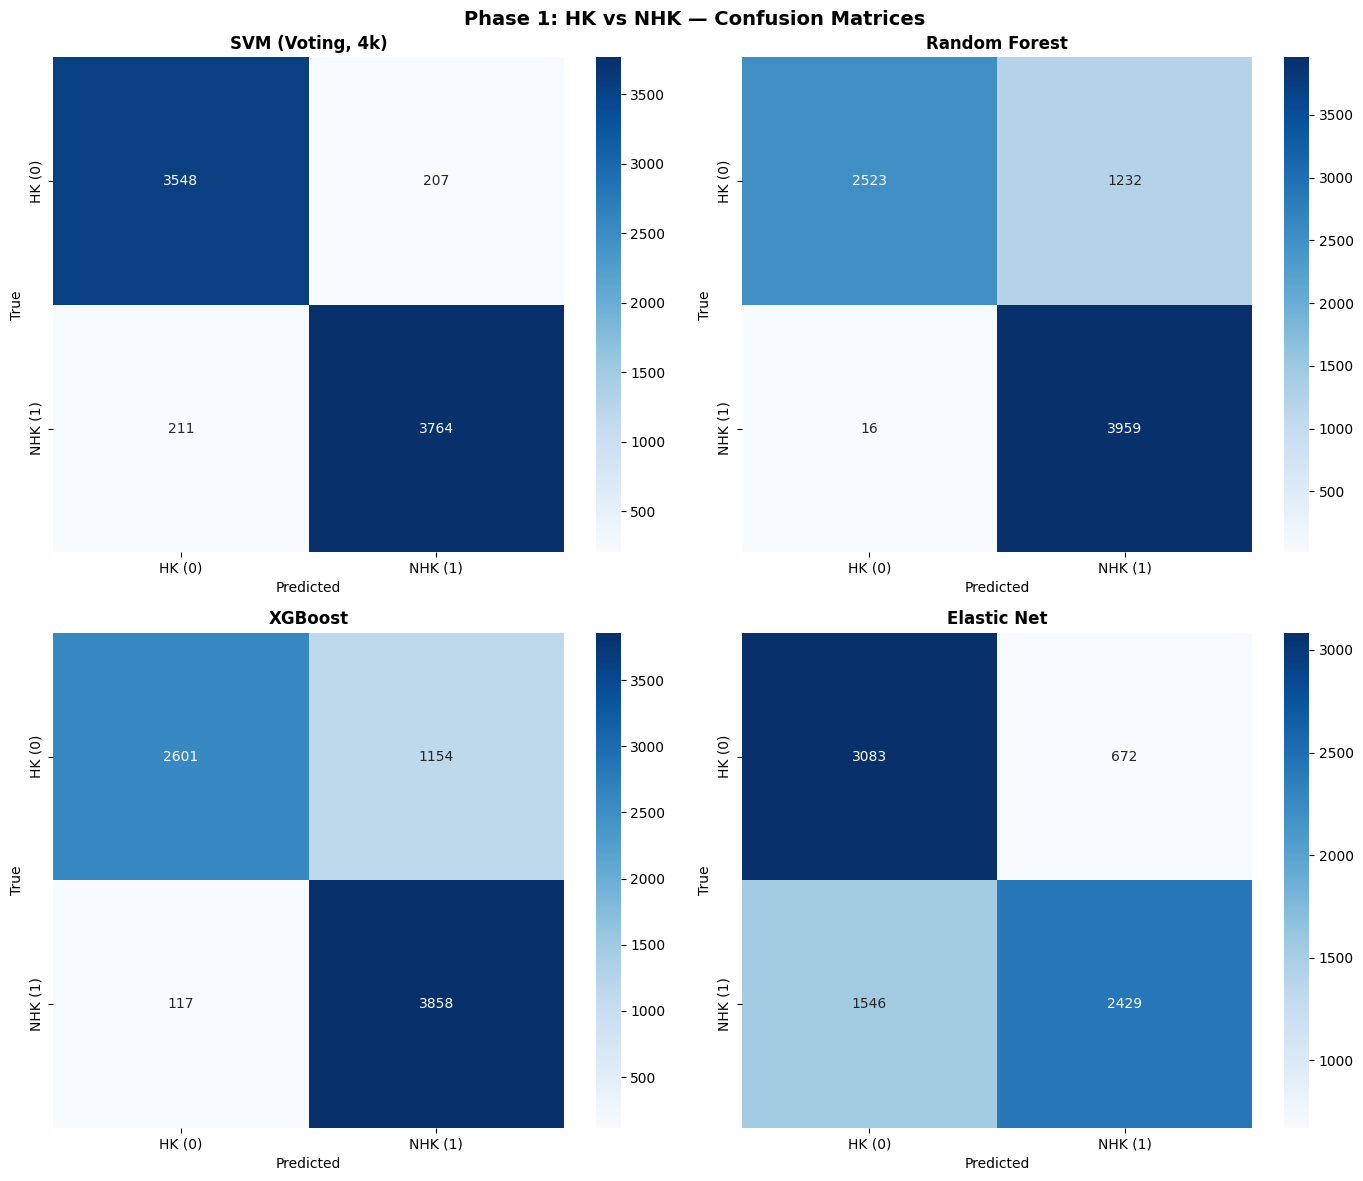

In [47]:
# ── Phase 1: Confusion Matrices ──
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
model_names_p1 = ['SVM (Voting, 4k)', 'Random Forest', 'XGBoost', 'Elastic Net']
predictions_p1 = [svm_pred, rf_pred, xgb_pred, enet_pred]

for ax, name, pred in zip(axes.flatten(), model_names_p1, predictions_p1):
    cm = confusion_matrix(y_test_p1, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['HK (0)', 'NHK (1)'], yticklabels=['HK (0)', 'NHK (1)'])
    ax.set_title(f'{name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.suptitle('Phase 1: HK vs NHK — Confusion Matrices', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

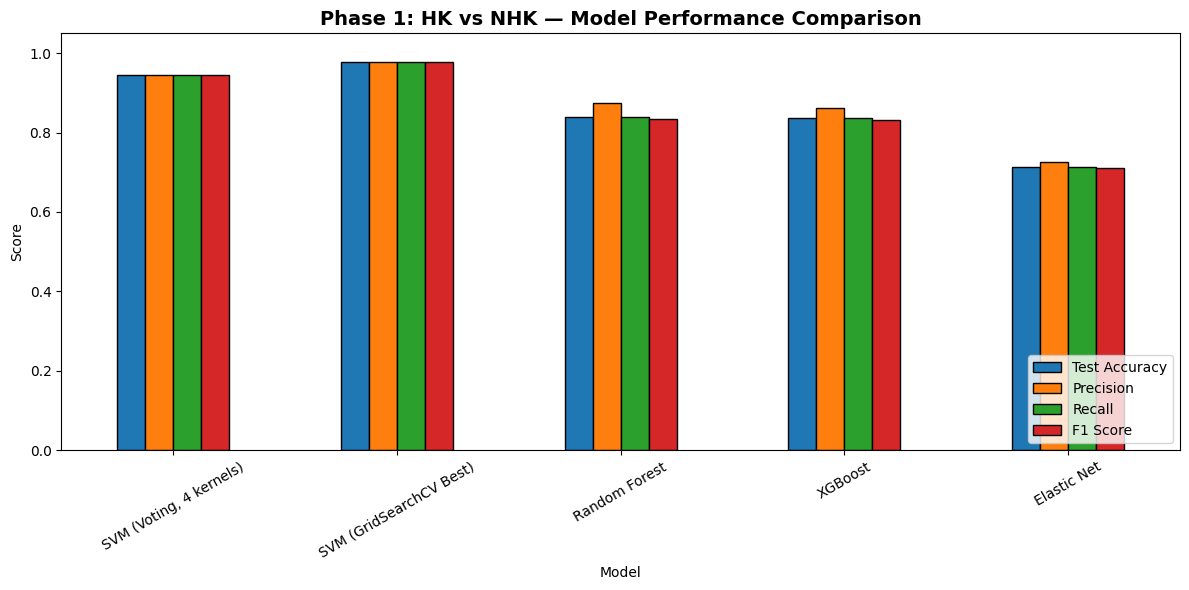

In [48]:
# ── Phase 1: Metrics Bar Chart ──
metrics_df = phase1_results.set_index('Model')[['Test Accuracy', 'Precision', 'Recall', 'F1 Score']]
ax = metrics_df.plot(kind='bar', figsize=(12, 6), rot=30, edgecolor='black')
ax.set_title('Phase 1: HK vs NHK — Model Performance Comparison', fontsize=14, fontweight='bold')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Phase 2: NHK Multi-class Tissue Classification

Using `Supplementary File 3.xlsx` which contains the 14,936 NHK genes with tissue-preferential labels in the `Resultant` column.
Multi-label classification using OneVsRestClassifier.

In [49]:
# ── Phase 2: Load NHK classified data ──
nhk_data = pd.read_excel('Supplementary File 3.xlsx')
print(f'NHK dataset shape: {nhk_data.shape}')
print(f'Columns: {list(nhk_data.columns)}')
print(f'\nFirst few rows:')
nhk_data.head()

NHK dataset shape: (19446, 9)
Columns: ['Transcript id', 'RT', 'GT', 'FP', 'FDS', 'ST', 'Total Difference', 'Particular', 'Resultant']

First few rows:


,Transcript id,RT,GT,FP,FDS,ST,Total Difference,Particular,Resultant
0,Ca_00003,2.841208,3.368885,3.249552,3.853562,3.254796,0,NaN,NaN
1,Ca_00004,2.937289,3.708105,4.355468,4.106321,3.580919,0,NaN,NaN
2,Ca_00006,4.313601,4.237663,5.116702,4.567990,3.599209,0,NaN,NaN
3,Ca_00010,2.041889,2.353907,2.624979,3.088064,2.537327,0,NaN,NaN
4,Ca_00012,1.022811,1.988546,0.918831,2.196682,0.609123,3,"RT-FDS, FP-FDS, FDS-ST",FDS


In [50]:
# ── Phase 2: Prepare features and multi-label target ──
tissue_names = ['RT', 'GT', 'FP', 'FDS', 'ST']

X_phase2 = nhk_data[tissue_names].copy()
y_raw = nhk_data['Resultant'].copy()
groups_phase2 = nhk_data['Transcript id'].map(chromosome_by_transcript)

if groups_phase2.isna().any():
    raise ValueError('Missing chromosome group for one or more Phase 2 transcripts.')

# Convert comma-separated tissue labels to lists
#y_lists = y_raw.str.split(', ')    due to NaN, use next one
y_lists = y_raw.fillna('').apply(
    lambda x: [i.strip() for i in x.split(',')] if x else []
)

# Multi-label binarizer
mlb = MultiLabelBinarizer(classes=tissue_names)
y_phase2 = mlb.fit_transform(y_lists)

print(f'Feature shape: {X_phase2.shape}')
print(f'Label shape:   {y_phase2.shape}')
print(f'\nLabel distribution per tissue:')
for i, name in enumerate(tissue_names):
    print(f'  {name}: {y_phase2[:, i].sum()} genes')

# Chromosome-level holdout: a chromosome/scaffold group cannot occur in both sets.
train_idx_p2, test_idx_p2 = chromosome_group_split(
    X_phase2, y_phase2, groups_phase2, test_size=0.2, random_state=42
)
X_train_p2, X_test_p2 = X_phase2.iloc[train_idx_p2], X_phase2.iloc[test_idx_p2]
y_train_p2, y_test_p2 = y_phase2[train_idx_p2], y_phase2[test_idx_p2]
groups_train_p2 = groups_phase2.iloc[train_idx_p2]

group_cv_p2 = GroupKFold(n_splits=min(5, groups_phase2.nunique()))

print(f'\nTrain: {X_train_p2.shape[0]}, Test: {X_test_p2.shape[0]} '
      f'({X_test_p2.shape[0] / len(X_phase2):.1%})')
print(f'Train groups: {sorted(groups_train_p2.unique())}')
print(f'Test groups:  {sorted(groups_phase2.iloc[test_idx_p2].unique())}')


Feature shape: (19446, 5)
Label shape:   (19446, 5)

Label distribution per tissue:
  RT: 6675 genes
  GT: 3087 genes
  FP: 2897 genes
  FDS: 3623 genes
  ST: 3491 genes

Train: 15493, Test: 3953 (20.3%)
Train groups: ['Ca_1', 'Ca_2', 'Ca_3', 'Ca_5', 'Ca_6', 'Ca_7', 'Unplaced']
Test groups:  ['Ca_4', 'Ca_8']


### Phase 2 Model 1: SVM (OneVsRest)

In [51]:
# ── Phase 2: SVM via OneVsRestClassifier (regularized, 4 kernels) ──
svm_p2_base = VotingClassifier(
    estimators=[
        ('linear', SVC(kernel='linear', C=0.5, probability=True, random_state=42)),
        ('rbf', SVC(kernel='rbf', C=0.5, probability=True, random_state=42)),
        ('poly2', SVC(kernel='poly', degree=2, C=0.5, probability=True, random_state=42)),
        ('poly3', SVC(kernel='poly', degree=3, C=0.5, probability=True, random_state=42))
    ],
    voting='soft'
)
svm_p2 = OneVsRestClassifier(svm_p2_base, n_jobs=-1)
svm_p2.fit(X_train_p2, y_train_p2)
svm_p2_pred = svm_p2.predict(X_test_p2)

print('SVM (OneVsRest, 4 kernels, C=0.5) Classification Report:')
print(classification_report(y_test_p2, svm_p2_pred, target_names=tissue_names, zero_division=0))

# Cross-validation for SVM
from sklearn.model_selection import cross_val_predict
svm_p2_cv = OneVsRestClassifier(
    VotingClassifier(
        estimators=[
            ('linear', SVC(kernel='linear', C=0.5, probability=True, random_state=42)),
            ('rbf', SVC(kernel='rbf', C=0.5, probability=True, random_state=42)),
            ('poly2', SVC(kernel='poly', degree=2, C=0.5, probability=True, random_state=42)),
            ('poly3', SVC(kernel='poly', degree=3, C=0.5, probability=True, random_state=42))
        ],
        voting='soft'
    ), n_jobs=-1
)
svm_cv_pred = cross_val_predict(svm_p2_cv, X_phase2, y_phase2, cv=group_cv_p2, groups=groups_phase2)
print('\nChromosome-Grouped Cross-Validation Report (SVM):')
print(classification_report(y_phase2, svm_cv_pred, target_names=tissue_names, zero_division=0))
print(f'CV F1 (macro): {f1_score(y_phase2, svm_cv_pred, average="macro", zero_division=0):.4f}')
print(f'CV F1 (micro): {f1_score(y_phase2, svm_cv_pred, average="micro", zero_division=0):.4f}')

SVM (OneVsRest, 4 kernels, C=0.5) Classification Report:
              precision    recall  f1-score   support

          RT       0.94      0.81      0.87      1315
          GT       0.89      0.75      0.81       629
          FP       0.91      0.72      0.80       585
         FDS       0.90      0.76      0.82       758
          ST       0.94      0.74      0.83       728

   micro avg       0.92      0.77      0.83      4015
   macro avg       0.91      0.76      0.83      4015
weighted avg       0.92      0.77      0.83      4015
 samples avg       0.50      0.48      0.48      4015


Chromosome-Grouped Cross-Validation Report (SVM):
              precision    recall  f1-score   support

          RT       0.94      0.83      0.88      6675
          GT       0.91      0.74      0.82      3087
          FP       0.92      0.71      0.80      2897
         FDS       0.90      0.75      0.82      3623
          ST       0.93      0.76      0.84      3491

   micro avg       0.92

### Phase 2 Model 2: Random Forest (OneVsRest)

In [52]:
# ── Phase 2: Random Forest via OneVsRestClassifier ──
rf_p2 = OneVsRestClassifier(
    RandomForestClassifier(
        n_estimators=150,
        max_depth=8,
        min_samples_split=5,
        min_samples_leaf=3,
        max_features='sqrt',
        random_state=42,
        n_jobs=-1
    ),
    n_jobs=-1
)
rf_p2.fit(X_train_p2, y_train_p2)
rf_p2_pred = rf_p2.predict(X_test_p2)

print('Random Forest (OneVsRest, regularized) Classification Report:')
print(classification_report(y_test_p2, rf_p2_pred, target_names=tissue_names, zero_division=0))

# Cross-validation for RF
from sklearn.model_selection import cross_val_predict
rf_p2_cv = OneVsRestClassifier(
    RandomForestClassifier(
        n_estimators=150, max_depth=8, min_samples_split=5,
        min_samples_leaf=3, max_features='sqrt', random_state=42, n_jobs=-1
    ), n_jobs=-1
)
rf_cv_pred = cross_val_predict(rf_p2_cv, X_phase2, y_phase2, cv=group_cv_p2, groups=groups_phase2)
print('\nChromosome-Grouped Cross-Validation Report (Random Forest):')
print(classification_report(y_phase2, rf_cv_pred, target_names=tissue_names, zero_division=0))
print(f'CV F1 (macro): {f1_score(y_phase2, rf_cv_pred, average="macro", zero_division=0):.4f}')
print(f'CV F1 (micro): {f1_score(y_phase2, rf_cv_pred, average="micro", zero_division=0):.4f}')

Random Forest (OneVsRest, regularized) Classification Report:
              precision    recall  f1-score   support

          RT       0.97      0.70      0.82      1315
          GT       0.96      0.65      0.77       629
          FP       1.00      0.43      0.60       585
         FDS       0.93      0.62      0.74       758
          ST       0.98      0.45      0.62       728

   micro avg       0.97      0.59      0.73      4015
   macro avg       0.97      0.57      0.71      4015
weighted avg       0.97      0.59      0.73      4015
 samples avg       0.42      0.37      0.38      4015


Chromosome-Grouped Cross-Validation Report (Random Forest):
              precision    recall  f1-score   support

          RT       0.97      0.71      0.82      6675
          GT       0.96      0.64      0.77      3087
          FP       0.99      0.45      0.62      2897
         FDS       0.93      0.61      0.74      3623
          ST       0.98      0.49      0.65      3491

   micro

### Phase 2 Model 3: XGBoost (OneVsRest)

In [53]:
# ── Phase 2: XGBoost via OneVsRestClassifier ──
xgb_p2 = OneVsRestClassifier(
    XGBClassifier(
        n_estimators=150,
        max_depth=4,
        learning_rate=0.08,
        reg_alpha=0.5,
        reg_lambda=3.0,
        subsample=0.85,
        colsample_bytree=0.85,
        min_child_weight=3,
        use_label_encoder=False,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ),
    n_jobs=-1
)
xgb_p2.fit(X_train_p2, y_train_p2)
xgb_p2_pred = xgb_p2.predict(X_test_p2)

print('XGBoost (OneVsRest, regularized) Classification Report:')
print(classification_report(y_test_p2, xgb_p2_pred, target_names=tissue_names, zero_division=0))

# Cross-validation for XGBoost
from sklearn.model_selection import cross_val_predict
xgb_p2_cv = OneVsRestClassifier(
    XGBClassifier(
        n_estimators=150, max_depth=4, learning_rate=0.08,
        reg_alpha=0.5, reg_lambda=3.0, subsample=0.85, colsample_bytree=0.85,
        min_child_weight=3, use_label_encoder=False, eval_metric='logloss',
        random_state=42, n_jobs=-1
    ), n_jobs=-1
)
xgb_cv_pred = cross_val_predict(xgb_p2_cv, X_phase2, y_phase2, cv=group_cv_p2, groups=groups_phase2)
print('\nChromosome-Grouped Cross-Validation Report (XGBoost):')
print(classification_report(y_phase2, xgb_cv_pred, target_names=tissue_names, zero_division=0))
print(f'CV F1 (macro): {f1_score(y_phase2, xgb_cv_pred, average="macro", zero_division=0):.4f}')
print(f'CV F1 (micro): {f1_score(y_phase2, xgb_cv_pred, average="micro", zero_division=0):.4f}')

XGBoost (OneVsRest, regularized) Classification Report:
              precision    recall  f1-score   support

          RT       0.95      0.82      0.88      1315
          GT       0.93      0.76      0.84       629
          FP       0.97      0.63      0.76       585
         FDS       0.94      0.77      0.85       758
          ST       0.98      0.71      0.82       728

   micro avg       0.95      0.75      0.84      4015
   macro avg       0.95      0.74      0.83      4015
weighted avg       0.95      0.75      0.84      4015
 samples avg       0.51      0.48      0.49      4015


Chromosome-Grouped Cross-Validation Report (XGBoost):
              precision    recall  f1-score   support

          RT       0.96      0.82      0.89      6675
          GT       0.93      0.74      0.83      3087
          FP       0.96      0.62      0.75      2897
         FDS       0.93      0.76      0.83      3623
          ST       0.97      0.74      0.84      3491

   micro avg       0

### Phase 2 Model 4: Elastic Net (OneVsRest)

In [54]:
# ── Phase 2: Elastic Net via OneVsRestClassifier ──
enet_p2 = OneVsRestClassifier(
    SGDClassifier(
        loss='log_loss', penalty='elasticnet', l1_ratio=0.5,
        max_iter=1000, random_state=42
    ),
    n_jobs=-1
)
enet_p2.fit(X_train_p2, y_train_p2)
enet_p2_pred = enet_p2.predict(X_test_p2)

print('Elastic Net (OneVsRest) Classification Report:')
print(classification_report(y_test_p2, enet_p2_pred, target_names=tissue_names, zero_division=0))

# Cross-validation for Elastic Net
from sklearn.model_selection import cross_val_predict
enet_p2_cv = OneVsRestClassifier(
    SGDClassifier(
        loss='log_loss', penalty='elasticnet', l1_ratio=0.5,
        max_iter=1000, random_state=42
    ), n_jobs=-1
)
enet_cv_pred = cross_val_predict(enet_p2_cv, X_phase2, y_phase2, cv=group_cv_p2, groups=groups_phase2)
print('\nChromosome-Grouped Cross-Validation Report (Elastic Net):')
print(classification_report(y_phase2, enet_cv_pred, target_names=tissue_names, zero_division=0))
print(f'CV F1 (macro): {f1_score(y_phase2, enet_cv_pred, average="macro", zero_division=0):.4f}')
print(f'CV F1 (micro): {f1_score(y_phase2, enet_cv_pred, average="micro", zero_division=0):.4f}')

Elastic Net (OneVsRest) Classification Report:
              precision    recall  f1-score   support

          RT       0.80      0.28      0.42      1315
          GT       0.98      0.31      0.47       629
          FP       0.55      0.58      0.57       585
         FDS       0.82      0.68      0.74       758
          ST       1.00      0.00      0.01       728

   micro avg       0.74      0.36      0.48      4015
   macro avg       0.83      0.37      0.44      4015
weighted avg       0.83      0.36      0.44      4015
 samples avg       0.24      0.20      0.21      4015


Chromosome-Grouped Cross-Validation Report (Elastic Net):
              precision    recall  f1-score   support

          RT       0.53      0.23      0.32      6675
          GT       0.88      0.52      0.65      3087
          FP       0.72      0.33      0.45      2897
         FDS       0.89      0.49      0.63      3623
          ST       0.88      0.01      0.03      3491

   micro avg       0.73  

### Phase 2: Model Comparison

In [55]:
# ── Phase 2: Benchmark Comparison Table (with CV results) ──
p2_models = ['SVM (OVR)', 'Random Forest (OVR)', 'XGBoost (OVR)', 'Elastic Net (OVR)']
p2_preds = [svm_p2_pred, rf_p2_pred, xgb_p2_pred, enet_p2_pred]
p2_cv_preds = [svm_cv_pred, rf_cv_pred, xgb_cv_pred, enet_cv_pred]

phase2_results = []
for name, pred, cv_pred in zip(p2_models, p2_preds, p2_cv_preds):
    phase2_results.append({
        'Model': name,
        'Precision (macro)': precision_score(y_test_p2, pred, average='macro', zero_division=0),
        'Recall (macro)': recall_score(y_test_p2, pred, average='macro', zero_division=0),
        'F1 (macro)': f1_score(y_test_p2, pred, average='macro', zero_division=0),
        'F1 (micro)': f1_score(y_test_p2, pred, average='micro', zero_division=0),
        'CV F1 (macro)': f1_score(y_phase2, cv_pred, average='macro', zero_division=0),
        'CV F1 (micro)': f1_score(y_phase2, cv_pred, average='micro', zero_division=0),
    })

phase2_df = pd.DataFrame(phase2_results)
print('\n' + '='*100)
print('PHASE 2: NHK TISSUE CLASSIFICATION — MODEL BENCHMARK COMPARISON (with 5-Fold CV)')
print('='*100)
print(phase2_df.to_string(index=False))


PHASE 2: NHK TISSUE CLASSIFICATION — MODEL BENCHMARK COMPARISON (with 5-Fold CV)
              Model  Precision (macro)  Recall (macro)  F1 (macro)  F1 (micro)  CV F1 (macro)  CV F1 (micro)
          SVM (OVR)           0.913268        0.756423    0.827186    0.834917       0.830397       0.840111
Random Forest (OVR)           0.968061        0.569854    0.710334    0.734681       0.720102       0.743815
      XGBoost (OVR)           0.953727        0.737678    0.829942    0.840846       0.825730       0.839255
  Elastic Net (OVR)           0.829451        0.371647    0.441175    0.480782       0.416567       0.424514


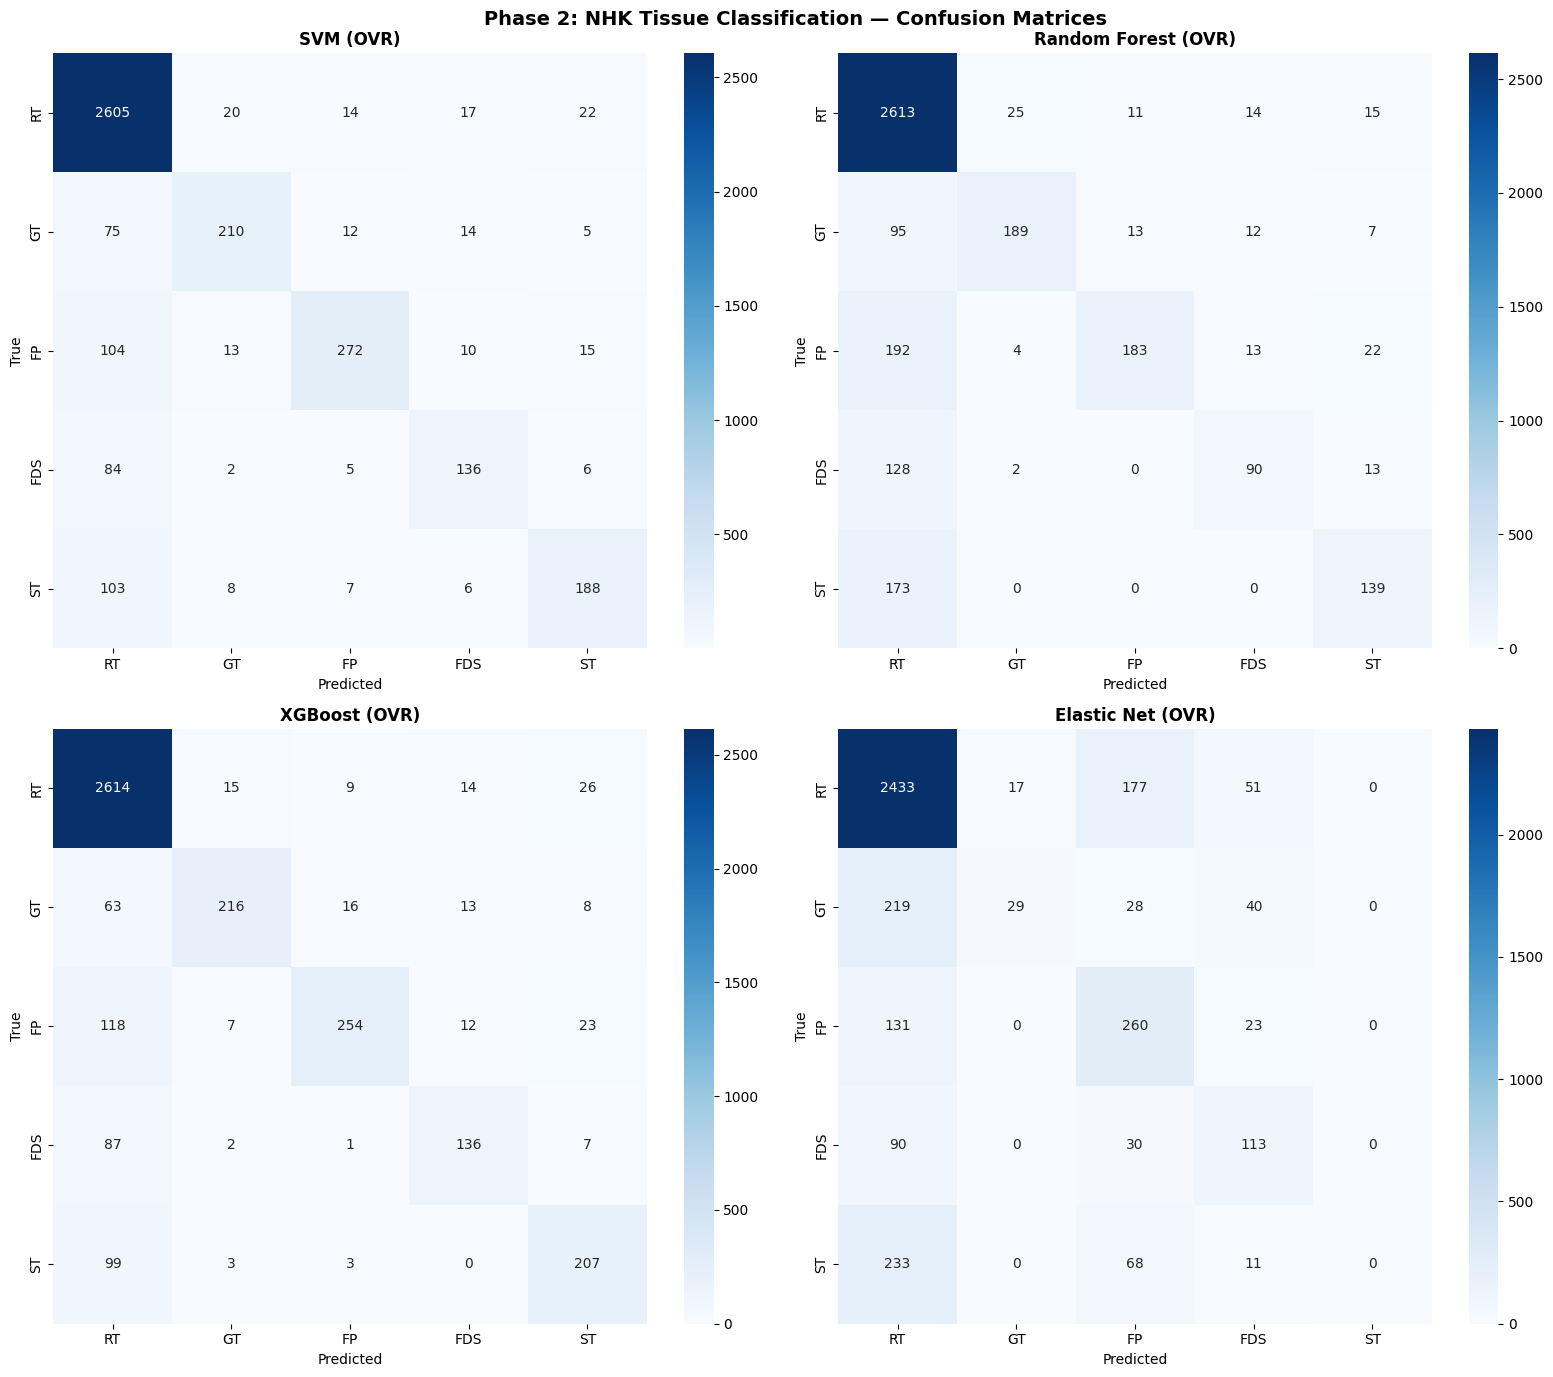

In [56]:
# ── Phase 2: Confusion Matrices (argmax-based for visualization) ──
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

for ax, name, pred in zip(axes.flatten(), p2_models, p2_preds):
    # Use argmax for single-label confusion matrix approximation
    cm = confusion_matrix(y_test_p2.argmax(axis=1), pred.argmax(axis=1),
                          labels=np.arange(len(tissue_names)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=tissue_names, yticklabels=tissue_names)
    ax.set_title(f'{name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.suptitle('Phase 2: NHK Tissue Classification — Confusion Matrices', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

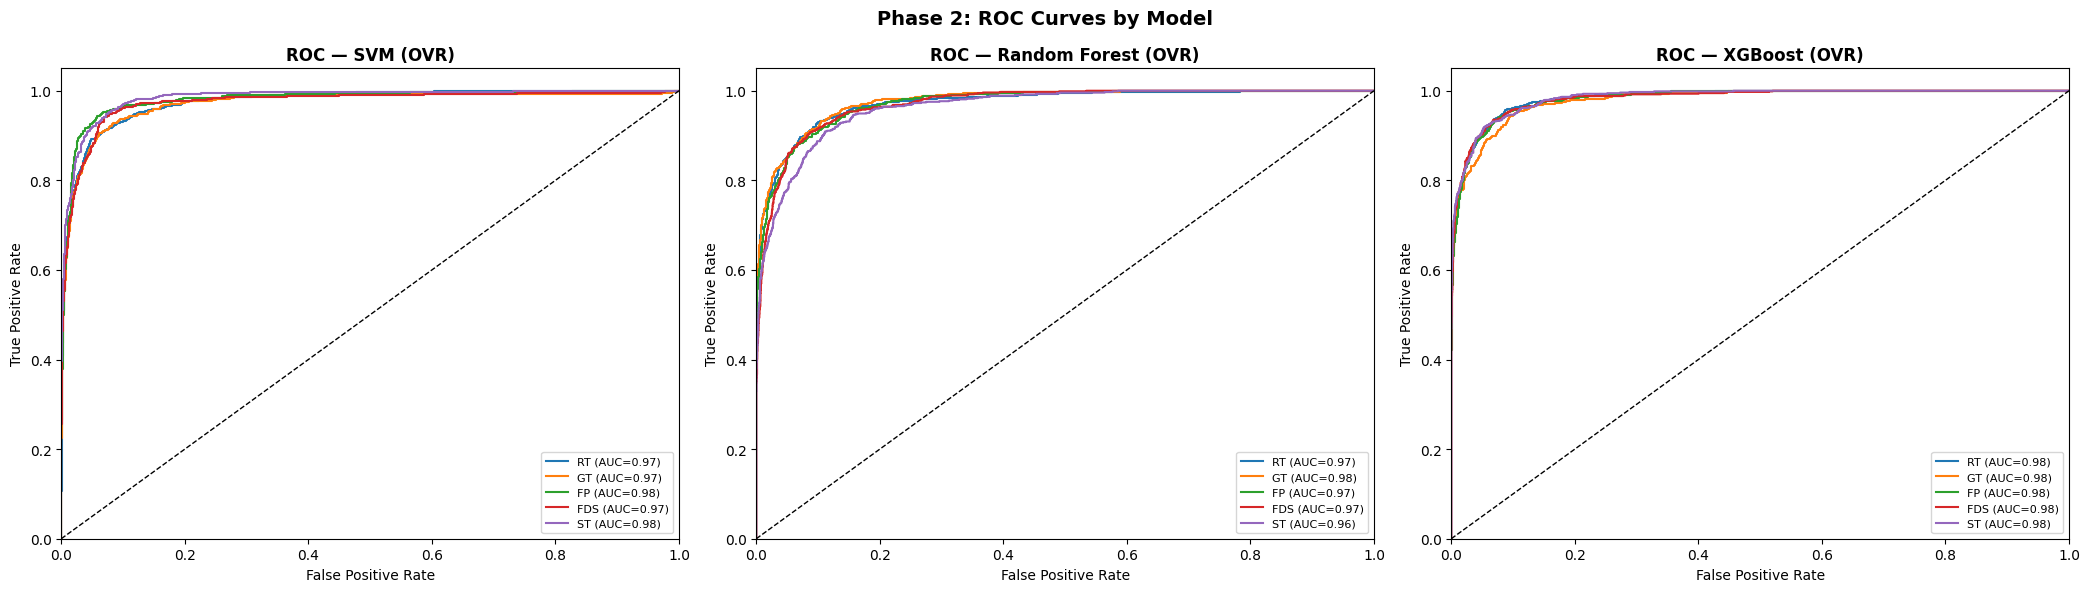

In [57]:
# ── Phase 2: ROC-AUC Curves ──
# Use models that support predict_proba
roc_models = {
    'SVM (OVR)': svm_p2,
    'Random Forest (OVR)': rf_p2,
    'XGBoost (OVR)': xgb_p2,
}

fig, axes = plt.subplots(1, len(roc_models), figsize=(7*len(roc_models), 6))
if len(roc_models) == 1:
    axes = [axes]

for ax, (model_name, model) in zip(axes, roc_models.items()):
    try:
        y_score = model.predict_proba(X_test_p2)
    except AttributeError:
        y_score = model.decision_function(X_test_p2)

    for i, tname in enumerate(tissue_names):
        fpr_i, tpr_i, _ = roc_curve(y_test_p2[:, i], y_score[:, i])
        auc_i = auc(fpr_i, tpr_i)
        ax.plot(fpr_i, tpr_i, label=f'{tname} (AUC={auc_i:.2f})')

    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f'ROC — {model_name}', fontweight='bold')
    ax.legend(loc='lower right', fontsize=8)

plt.suptitle('Phase 2: ROC Curves by Model', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Phase 2: Precision-Recall (PR) AUC Curves

**Why PR curves instead of ROC curves?**

ROC-AUC can be misleadingly high for imbalanced multi-label classification tasks because it accounts for True Negatives (which are typically abundant). Precision-Recall curves focus exclusively on the positive class predictions, making them more informative and realistic for evaluating model performance on imbalanced datasets.

A high ROC-AUC (0.95+) does NOT necessarily mean the model performs well — PR-AUC gives a more honest picture.

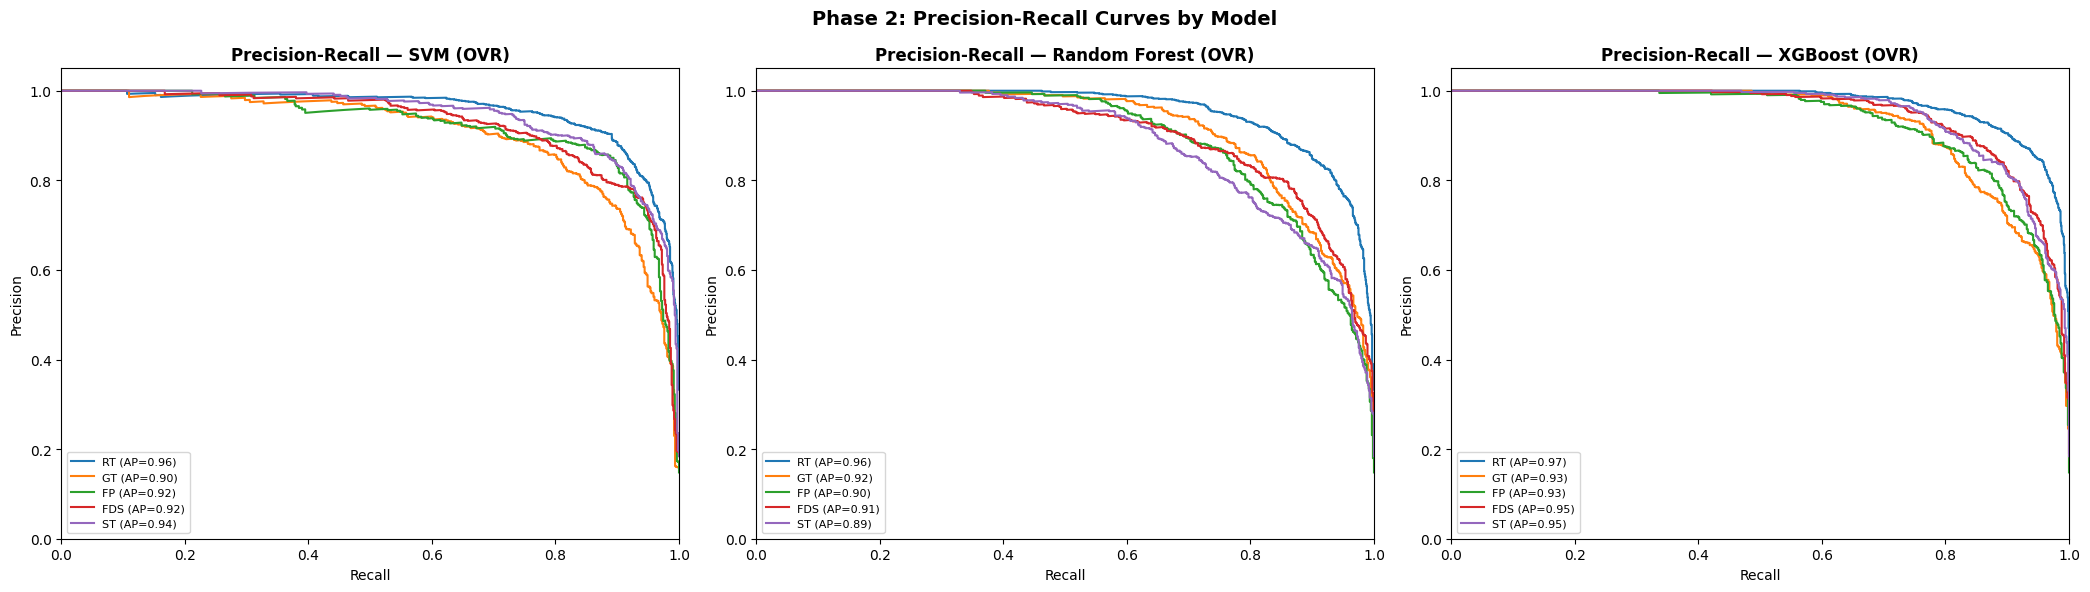


PHASE 2: PRECISION-RECALL AUC (Average Precision) SUMMARY
Model                             RT         GT         FP        FDS         ST    Mean AP
------------------------------------------------------------------------------------------
SVM (OVR)                     0.9551     0.9029     0.9204     0.9248     0.9432     0.9293
Random Forest (OVR)           0.9557     0.9152     0.8977     0.9058     0.8865     0.9122
XGBoost (OVR)                 0.9709     0.9258     0.9278     0.9467     0.9470     0.9436


In [58]:
# ── Phase 2: Precision-Recall (PR) AUC Curves ──
from sklearn.metrics import precision_recall_curve, average_precision_score

# Models that support predict_proba
pr_models = {
    'SVM (OVR)': svm_p2,
    'Random Forest (OVR)': rf_p2,
    'XGBoost (OVR)': xgb_p2,
}

fig, axes = plt.subplots(1, len(pr_models), figsize=(7*len(pr_models), 6))
if len(pr_models) == 1:
    axes = [axes]

for ax, (model_name, model) in zip(axes, pr_models.items()):
    try:
        y_score = model.predict_proba(X_test_p2)
    except AttributeError:
        y_score = model.decision_function(X_test_p2)

    for i, tname in enumerate(tissue_names):
        precision_i, recall_i, _ = precision_recall_curve(y_test_p2[:, i], y_score[:, i])
        ap_i = average_precision_score(y_test_p2[:, i], y_score[:, i])
        ax.plot(recall_i, precision_i, label=f'{tname} (AP={ap_i:.2f})')

    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_title(f'Precision-Recall — {model_name}', fontweight='bold')
    ax.legend(loc='lower left', fontsize=8)

plt.suptitle('Phase 2: Precision-Recall Curves by Model', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ── Print PR-AUC (Average Precision) summary table ──
print('\n' + '='*90)
print('PHASE 2: PRECISION-RECALL AUC (Average Precision) SUMMARY')
print('='*90)
print(f'{"Model":<25} ', end='')
for tname in tissue_names:
    print(f'{tname:>10} ', end='')
print(f'{"Mean AP":>10}')
print('-' * 90)

for model_name, model in pr_models.items():
    try:
        y_score = model.predict_proba(X_test_p2)
    except AttributeError:
        y_score = model.decision_function(X_test_p2)

    aps = []
    print(f'{model_name:<25} ', end='')
    for i, tname in enumerate(tissue_names):
        ap_i = average_precision_score(y_test_p2[:, i], y_score[:, i])
        aps.append(ap_i)
        print(f'{ap_i:>10.4f} ', end='')
    mean_ap = sum(aps) / len(aps)
    print(f'{mean_ap:>10.4f}')

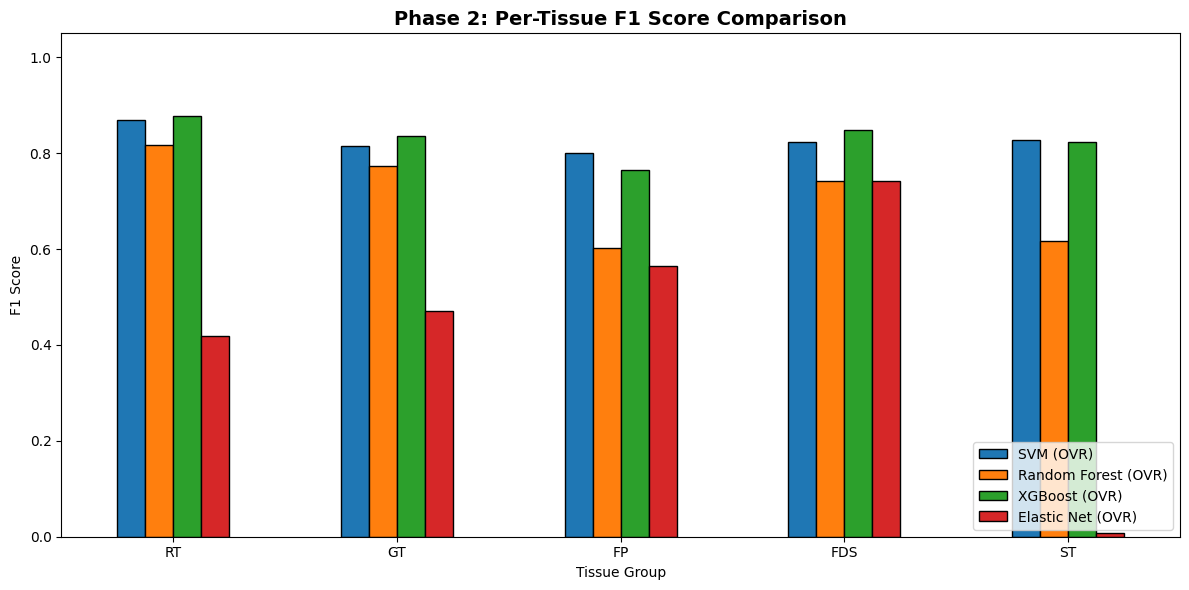

In [59]:
# ── Phase 2: Per-class F1 Score Comparison ──
f1_per_class = {}
for name, pred in zip(p2_models, p2_preds):
    report = classification_report(y_test_p2, pred, target_names=tissue_names,
                                   output_dict=True, zero_division=0)
    f1_per_class[name] = [report[t]['f1-score'] for t in tissue_names]

f1_df = pd.DataFrame(f1_per_class, index=tissue_names)

ax = f1_df.plot(kind='bar', figsize=(12, 6), edgecolor='black')
ax.set_title('Phase 2: Per-Tissue F1 Score Comparison', fontsize=14, fontweight='bold')
ax.set_ylabel('F1 Score')
ax.set_xlabel('Tissue Group')
ax.set_ylim(0, 1.05)
ax.legend(loc='lower right')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Summary

The pipeline has completed both phases of classification:

1. **Phase 1 (HK vs NHK)**: Compared SVM, Random Forest, XGBoost, and Elastic Net for binary classification
2. **Phase 2 (Tissue Classification)**: Compared the same models using OneVsRestClassifier for multi-label tissue-preferential gene classification

Results are collected in `phase1_results` and `phase2_df` DataFrames for further analysis.

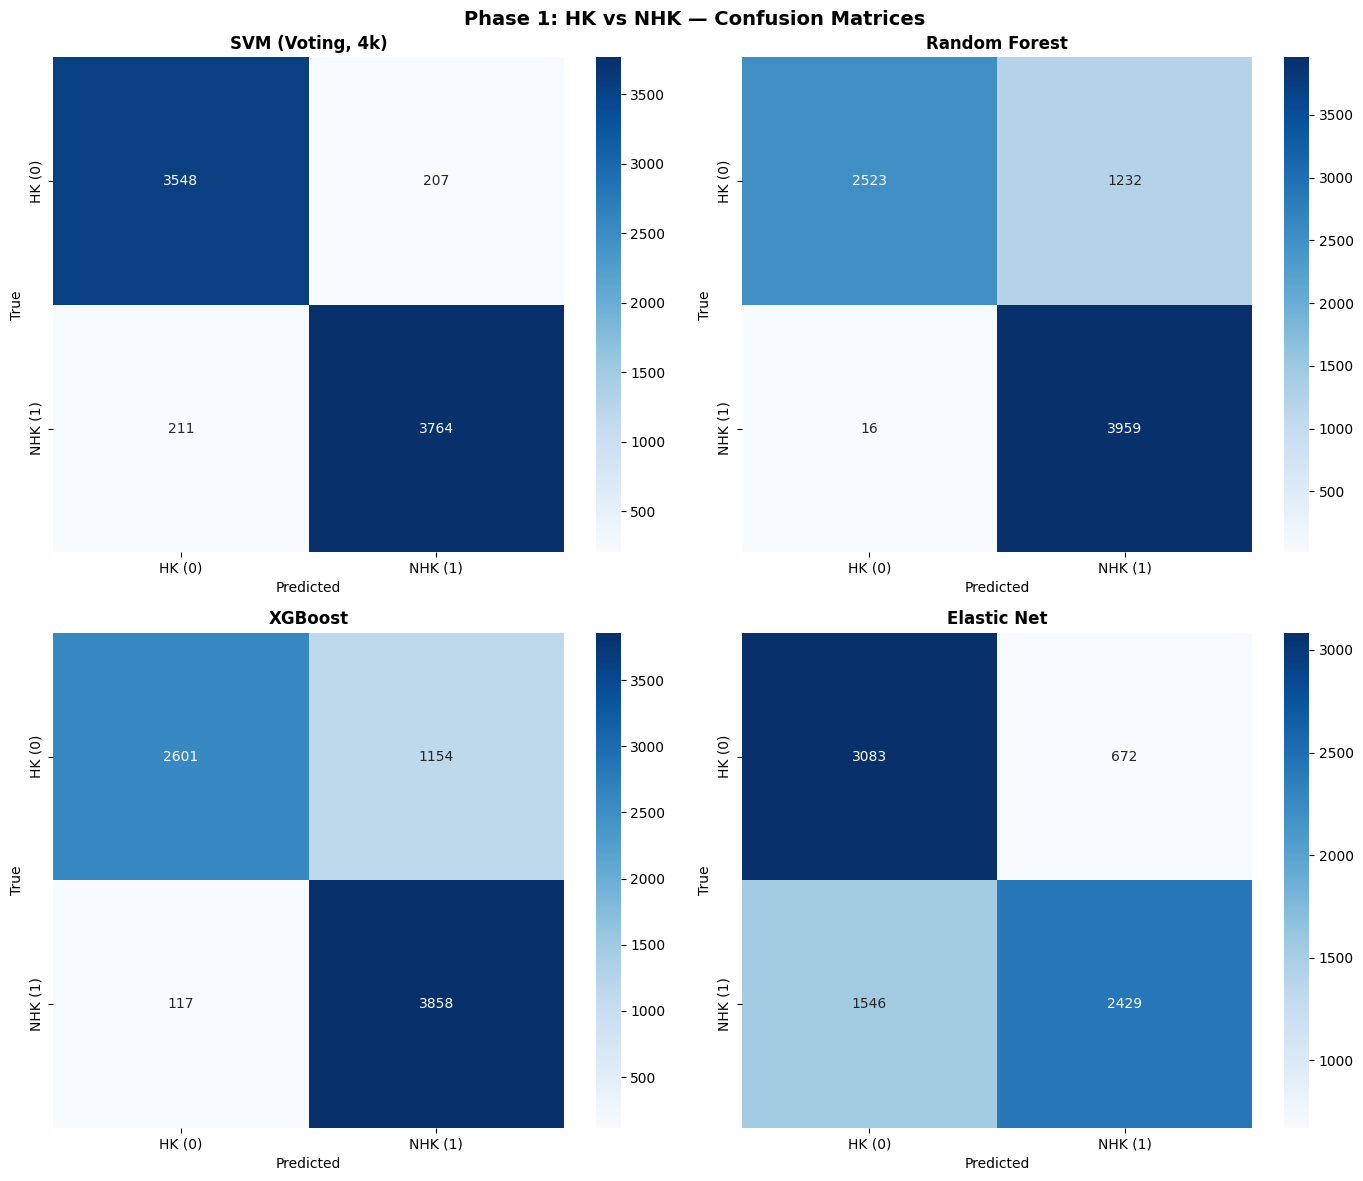

In [60]:
# ── Phase 1: Confusion Matrices ──
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
model_names_p1 = ['SVM (Voting, 4k)', 'Random Forest', 'XGBoost', 'Elastic Net']
predictions_p1 = [svm_pred, rf_pred, xgb_pred, enet_pred]

for ax, name, pred in zip(axes.flatten(), model_names_p1, predictions_p1):
    cm = confusion_matrix(y_test_p1, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['HK (0)', 'NHK (1)'], yticklabels=['HK (0)', 'NHK (1)'])
    ax.set_title(f'{name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

plt.suptitle('Phase 1: HK vs NHK — Confusion Matrices', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

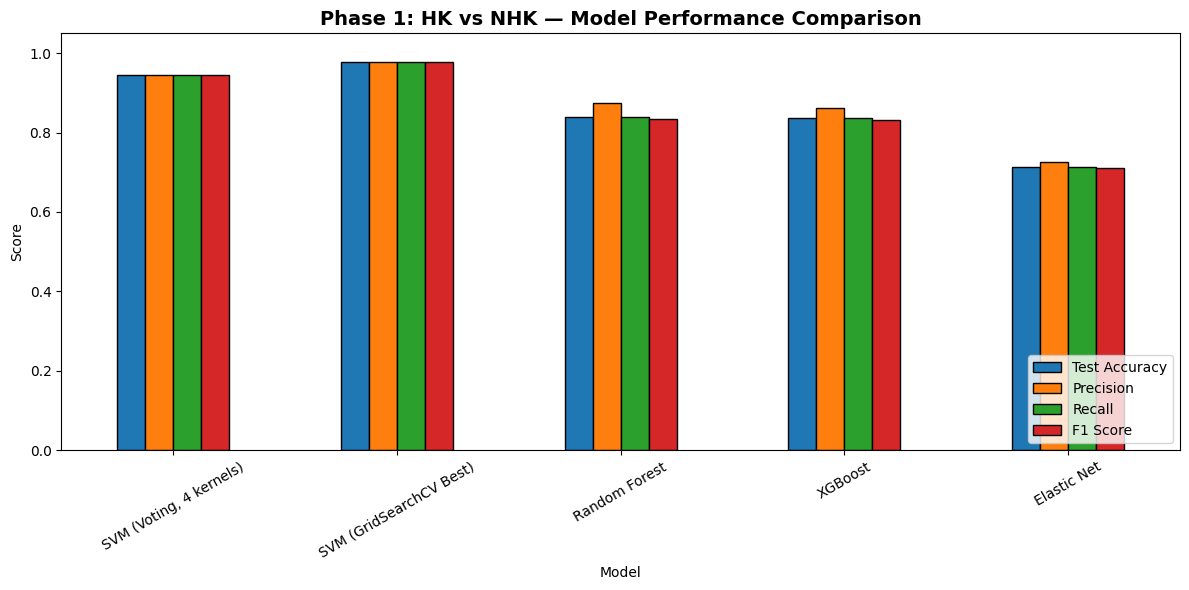

In [61]:
# ── Phase 1: Metrics Bar Chart ──
metrics_df = phase1_results.set_index('Model')[['Test Accuracy', 'Precision', 'Recall', 'F1 Score']]
ax = metrics_df.plot(kind='bar', figsize=(12, 6), rot=30, edgecolor='black')
ax.set_title('Phase 1: HK vs NHK — Model Performance Comparison', fontsize=14, fontweight='bold')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

#**STEP 8**: Functional Annotation

In [ ]:
go_obo = obo_parser.GODag("go-basic.obo") #Generic
gene2go_df = pd.read_excel("Supplementary File 7.xlsx", sheet_name="PCGs")

In [ ]:
gene2go = {}
for index, row in gene2go_df.iterrows():
    gene = row['Transcript id']
    go_terms = set()

    for column in ['GO (molecular function)', 'GO (cellular component)', 'GO (biological process)']:
        if pd.notna(row[column]):
            terms = row[column].split(';')
            for term in terms:
                go_id_match = re.search(r'\[GO:(\d+)\]', term)
                if go_id_match:
                    go_id = f"GO:{go_id_match.group(1)}"
                    go_terms.add(go_id)

    gene2go[gene] = go_terms

In [ ]:
total_genes = gene2go_df['Transcript id'].tolist()


go_enrichment = GOEnrichmentStudy(
    total_genes,
    gene2go,
    go_obo,
    methods=['fdr']
)

In [ ]:
excel_files = ["Seed Tissues.xlsx", "Root Tissues.xlsx", "Green Tissues.xlsx", "Flower Parts.xlsx", "Flower Development Stages.xlsx"]

output_dir = "interested"
os.makedirs(output_dir, exist_ok=True)

for excel_file in excel_files:
    df = pd.read_excel(excel_file)

    filtered_transcripts = df[df['Match'] == 1]['Transcript id']

    output_file = os.path.join(output_dir, f"{os.path.splitext(excel_file)[0]}-reactive.txt")

    filtered_transcripts_string = ",".join(filtered_transcripts.astype(str))

    with open(output_file, 'w') as f:
        f.write(filtered_transcripts_string)

    print(f"Filtered IDs written to {output_file}")

In [ ]:
input_dir = "interested"

reactive_files = [file for file in os.listdir(input_dir) if file.endswith('-reactive.txt')]

print("Available reactive files:")
for i, file in enumerate(reactive_files, start=1):
    print(f"{i}. {file}")

while True:
    try:
        choice = int(input("Enter the number corresponding to the file you want to use: "))
        if 1 <= choice <= len(reactive_files):
            selected_file = reactive_files[choice - 1]
            break
        else:
            print("...TryAgain...")
    except ValueError:
        print("...InValid")

selected_file_path = os.path.join(input_dir, selected_file)

with open(selected_file_path, 'r') as file:
    file_content = file.read()


reactive_genes = [x.strip() for x in file_content.split(',')]

results = go_enrichment.run_study(reactive_genes)

In [ ]:
results_df = pd.DataFrame([{
    'GO': result.GO,
    'Term': result.name,
    'Category': result.NS,
    'p_fdr': result.p_fdr,
    'Study_Count': result.study_count,
    'Population_Count': result.pop_count
} for result in results])

In [ ]:
results_df.info()

In [ ]:
print(results_df['p_fdr'].describe())

In [ ]:
low_p_fdr_terms = results_df[results_df['p_fdr'] == 0.0]
print("GO terms with p_fdr of 0:")
print(low_p_fdr_terms)

In [ ]:
significant_results = results_df[results_df['p_fdr'] < 0.05]

In [ ]:
plt.figure(figsize=(14, 20)) #100,60
sns.barplot(data=significant_results, x='p_fdr', y='Term', palette='viridis') #y='GO'
plt.title(f'Significant GO Terms for {selected_file}')
plt.xlabel('FDR Adjusted P-Value')
plt.ylabel('GO Term')
plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 6)) #100,60
sns.barplot(data=significant_results, x='p_fdr', y='Term', palette='viridis') #y='GO'
plt.title(f'Significant GO Terms for {selected_file}')
plt.xlabel('FDR Adjusted P-Value')
plt.ylabel('GO Term')
plt.tight_layout()
plt.show()

#**STEP 9**: Tissue Specific Distribution

**TSI Value Plots**

In [ ]:
file_path = 'Supplementary File 1.7.xlsx'
df = pd.read_excel(file_path)

df['TSI value (%)'] = df['TSI value'] * 100

plt.figure(figsize=(10, 6))
plt.bar(df['TSI tissue'], df['TSI value (%)'], color='skyblue')

plt.xlabel('Tissue Type')
plt.ylabel('TSI Value (%)')
plt.title('Tissue-Specific TSI Value Analysis')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**category wise TF, non-TF and lncRNA**

In [ ]:
#Add a new column in dataframe named Category to hold TF, non-TF and lncRNA
df['Category'] = 'non-TF' #Default
df.loc[df['lncRNA'].notna(), 'Category'] = 'lncRNA' #Check for NA
df.loc[df['TF family'].notna(), 'Category'] = 'TF'


category_counts = df['Category'].value_counts(normalize=True) * 100

plt.figure(figsize=(8, 6))
category_counts.plot(kind='bar', color=['#64cc4f', '#222222', '#b2e05b'])

plt.xlabel('Category')
plt.ylabel('Percentage (%)')
plt.title('Percentage Presence of lncRNA, TF, and non-TF in Dataset')

plt.xticks(rotation=0)
plt.legend(['non-TF', 'TF', 'lncRNA'], title='Category', loc='upper left')
plt.tight_layout()

plt.show()

**Stacked Bar Plots**

In [ ]:
df['Category'] = 'non-TF'
df.loc[df['lncRNA'].notna(), 'Category'] = 'lncRNA'
df.loc[df['TF family'].notna(), 'Category'] = 'TF'

#Group by 'TSI tissue' and calculate the percentage of each category
category_counts_by_tissue = df.groupby(['TSI tissue', 'Category']).size().unstack(fill_value=0)

# Normalize the counts to percentages within each tissue type
category_percentages = category_counts_by_tissue.div(category_counts_by_tissue.sum(axis=1), axis=0) * 100

category_percentages.plot(kind='bar', stacked=True, color=['#64cc4f', '#222222', '#b2e05b'], figsize=(10, 7))

plt.xlabel('TSI Tissue')
plt.ylabel('Percentage (%)')
plt.title('Tissue-Specific Distribution of lncRNA, TF, and non-TF')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

**Inverted Plots**

In [ ]:
category_percentages = category_percentages[['non-TF', 'TF', 'lncRNA']]

category_percentages.plot(kind='bar', stacked=True, color=['#64cc4f', '#222222', '#b2e05b'], figsize=(10, 7))

plt.xlabel('TSI Tissue')
plt.ylabel('Percentage (%)')
plt.title('Tissue-Specific Distribution of non-TF, TF, and lncRNA')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

**Rearranged According to Root dataset**

In [ ]:
custom_order = ['GS', 'S', 'R', 'Rtip', 'RH', 'YL', 'ML', 'Brac', 'SAM', 'FB1', 'FB2','FB3', 'FB4', 'FL1', 'FL2', 'FL3', 'FL4', 'FL5', 'Cal', 'Cor', 'And', 'Gyn', 'Pedi', 'PodSh', 'SdCt', 'Emb', 'Endo', '5 DAP', '10 DAP', '20  DAP', '30  DAP', 'Nod']

category_percentages = category_percentages.loc[custom_order]

category_percentages.plot(kind='bar', stacked=True, color=['#64cc4f', '#222222', '#b2e05b'], figsize=(12, 7))

plt.xlabel('TSI Tissue')
plt.ylabel('Percentage (%)')
plt.title('Tissue-Specific Distribution of non-TF, TF, and lncRNA')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()